# Step 2a — Build static soil-suitability layer from HWSD2

Climate-only SVM suitability (steps 2-3) can classify a pixel as "suitable" purely from
temperature/precipitation, even where the soil could never support the crop (shallow,
rocky, poorly drained, saline...). This notebook builds a **static, per-crop soil-suitability
index** (0-1) at the same 1° grid used everywhere else in the pipeline, from the
[HWSD2](https://www.fao.org/soils-portal/data-hub/soil-maps-and-databases/harmonized-world-soil-database-v20/en/)
(Harmonized World Soil Database v2.0/2.01, FAO/IIASA) raster + attribute database.

**Method — area-weighted index, in three levels**
1. The HWSD2 raster (30 arc-sec, ~1 km) gives a soil-unit ID (`HWSD2_SMU_ID`) per pixel.
   `HWSD2_LAYERS` lists the **components** of each unit (up to 12, with a share in %).
2. Each component gets a rating from 0 to 1 per crop (Section 4): **0 = unsuitable** if any severe
   limitation is violated (most-limiting factor, Sys et al. 1993); otherwise the **minimum of four
   graded ratings**, all from Sys's class ratings (1 = no limitation, 0.95 / 0.85 / 0.60 for slight /
   moderate / severe limitation): soil depth, coarse fragments, **pH** (two-tailed: acidity and
   alkalinity, both narrowing to a crop-specific optimum), and **texture** (Sys's own
   texture-structure class sequence, not raw USDA texture). A unit's rating is the **share-weighted**
   mean over its components.
3. For each 1° cell, the index is the **pixel-count-weighted** mean of the unit ratings over its
   120x120 native pixels → `soil_suit_idx_<crop>` in [0, 1].

Nothing is discarded: a cell that is 60% unsuitable clay and 40% suitable sand gets about 0.4 (not
0 or 1), and a cell of shallow, stony soil is penalised instead of counted as fully suitable. The
earlier approach (keep only the most frequent unit = first component of that unit) is kept **only
for comparison** and for the raw-property diagnostic maps.

**How the index is used downstream (4.b/4.c/4.d):** areas (Mha, country tables) are
climate-suitable cell area × index; the change-map categories need a binary layer, so they use
`soil_suit_bin_<crop>` = index ≥ `TAU_MAP` (set to 0.40, Sys's own suitable/unsuitable S3/N1
boundary), with a sensitivity check on the cutoff in 4.b/4.c/4.d.

**Slope** (Section 5b) is included **only if a DEM is present** at `DEM_PATH` (config cell) —
HWSD2 itself has no slope variable, so this needs an external terrain source (e.g. Copernicus
GLO-90 from JRC BDAP); the section is a no-op otherwise, and the rest of the notebook is
unaffected either way.

**Not included**: permafrost (`ADD_PROP='Gelic'`) is deliberately excluded (see Section 4: a
climate signal already handled by the SVM); available water capacity (removed, see Section 4);
organic carbon (deliberately excluded — Sys itself never rates it below S3/0.60 in any crop, and
it is the most directly manageable property here, see Section 4); CEC (would double-count pH, see
Section 4).

**Input**:
- `0_Input_data/soil/HWSD2.bil` (+`.hdr`/`.prj`/`.stx`) — raster of `HWSD2_SMU_ID` codes, 30 arc-sec, NODATA=65535
- `0_Input_data/soil/HWSD2.mdb` — `HWSD2_SMU`, `HWSD2_LAYERS`, and the `D_*` code→label tables
- `1_preprocessing_BIOvariables/1.1)_preprocessing_biovariables_ERA5/outputs_ERA5/BIOvariables_ERA5_1981_2015_1deg_<crop>.nc` — 1° grid + land mask

**Output**: `soil_suitability_outputs/soil_suitability_HWSD_1deg.nc` — per crop:
`soil_suit_idx_<crop>` (0-1), `soil_suit_bin_<crop>` (index ≥ TAU_MAP) and
`soil_suit_bin_dominant_<crop>` (old dominant-unit version), plus diagnostic PNGs.

**Rule provenance**: thresholds and ratings are from Sys, Van Ranst & Debaveye (1993), *Land
Evaluation Part III: Crop Requirements* (maize p.85, wheat p.178, general introduction pp.1-5) —
see Section 4. Crop-specific elements: the numeric chemistry limits (salinity, sodicity, carbonate,
gypsum), the pH bands, the soil-depth ratings, and the texture-structure ratings. Approximations:
the depth ratings assume a uniform depth distribution inside each HWSD class, maize's <20 cm limit
cannot be resolved by HWSD's classes, and 3 of wheat's 15 texture classes are interpolated rather
than read directly off the table (Section 4).

In [1]:
import os; os.environ.setdefault("HDF5_USE_FILE_LOCKING", "FALSE")   # BDAP/EOS refuses HDF5 file locks ("NetCDF: HDF error")
import json
import numpy as np
import pandas as pd
import xarray as xr
import rasterio
from rasterio.windows import Window
import matplotlib.pyplot as plt
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

BASE     = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "0_Input_data").is_dir())  # racine du projet (local ou BDAP)
import sys; sys.path.insert(0, str(BASE)); import crop_utils as cu   # helpers + config reader (project root)
CFG = cu.load_config()   # config/config_<profile>.json, written by 00_config_and_inventory.ipynb
SOIL_DIR = cu.data_dir(CFG, "hwsd_raster")  # data path: see 00_config_and_inventory.ipynb
OUT_DIR  = BASE / "1_SVM" / "2_soil_suitability" / "soil_suitability_outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  PARAMÈTRES — modifier ici, puis relancer les cellules marquées [RUN]  ║
# ╚══════════════════════════════════════════════════════════════════════════╝

CROPS = ['Maize_rf', 'Wheat-spring_rf', 'Wheat-winter_rf']   # only crops with trained SVMs

HWSD_RASTER_PATH = cu.data_file(CFG, "hwsd_raster")  # data path: see 00_config_and_inventory.ipynb
HWSD_MDB_PATH    = cu.data_file(CFG, "hwsd_mdb")  # data path: see 00_config_and_inventory.ipynb

# Soil-suitability index (0..1) per 1deg cell -> binary layer at this cutoff.
# For reference, Sys's boundary between suitable (S1-S3) and unsuitable (N1) is 0.40; 0.5 is used here.
# Areas (Mha) always use the index itself; TAU_MAP only sets the change-map categories.
TAU_MAP = 0.4

# --- Slope extension (Section 5b) -- optional, SKIPPED entirely if this file is not present ---
# Point this at a DEM (elevation) GeoTIFF once you have JRC BDAP access (e.g. Copernicus GLO-90).
# Any single-band raster works -- resolution/origin are read from its own affine transform, same
# as the HWSD raster above. Slope is computed from it, not read as a pre-made slope layer.
DEM_PATH = cu.data_file(CFG, "dem_slope")  # data path: see 00_config_and_inventory.ipynb
# Sys's slope table has 3 parallel rows (1)/(2)/(3), presumably different mechanization/erosion-risk
# assumptions -- exact definition not yet verified against Sys's introductory chapter (only the
# crop-page tables were read). Row 2 (0-2/2-4/4-8/8-16% breaks) is used as a middle-ground default;
# reconsider once the source page defining (1)/(2)/(3) is checked.
SLOPE_LEVEL = 2

print("Input files:")
for p in [HWSD_RASTER_PATH, HWSD_MDB_PATH]:
    print(f'  {"OK" if p.exists() else "MISSING"}: {p}')
print(f'  {"OK" if DEM_PATH.exists() else "MISSING (slope will be skipped)"}: {DEM_PATH}')

Input files:
  OK: C:\Users\elisa\OneDrive - Politecnico di Milano\PHD_codes\crop_suitability_code_bdap\0_Input_data\soil\HWSD2.bil
  OK: C:\Users\elisa\OneDrive - Politecnico di Milano\PHD_codes\crop_suitability_code_bdap\0_Input_data\soil\HWSD2.mdb
  MISSING (slope will be skipped): C:\Users\elisa\OneDrive - Politecnico di Milano\PHD_codes\crop_suitability_code_bdap\0_Input_data\soil\DEM_slope.tif


## 1. Target grid + land mask

Same 1° grid (37 lat x 70 lon, integer centres, lat 35-71, lon -25-44) as the rest of the pipeline. **The land mask is the single authoritative one used everywhere in this pipeline** (climate, soil, and the GAEZ comparison all restrict to exactly the same 1° pixels): the physical, crop-independent land/ocean mask defined once in step 1 (`1.a`, Section 1 — the NaN pattern of the bias-adjustment pipeline's masked ERA5 file), saved as `land_mask_1deg.nc`. It is not derived from any crop's BIO variables, and not from HWSD2's own land/sea split either (HWSD2's 30 arc-sec coastline and this mask's 1° ERA5 coastline disagree on many coastal cells — using two different coastlines for soil vs. climate/GAEZ was producing large, spurious differences on the coast, see Section 6 below). Soil properties themselves (Section 2 onward) are still computed from HWSD2 only.

In [3]:
LAND_MASK_NC = BASE / "1_SVM" / "0_preprocessing_masks" / "outputs_input_data_1deg" / "land_mask_1deg.nc"
ds_lm = xr.open_dataset(LAND_MASK_NC)
target_lats_asc = ds_lm.lat.values
target_lons     = ds_lm.lon.values
land_mask       = ds_lm['land_mask'].values.astype(bool)
ds_lm.close()

nlat, nlon = len(target_lats_asc), len(target_lons)
LAT_MIN_EDGE, LAT_MAX_EDGE = target_lats_asc[0] - 0.5, target_lats_asc[-1] + 0.5
LON_MIN_EDGE, LON_MAX_EDGE = target_lons[0] - 0.5, target_lons[-1] + 0.5

print(f"Target grid: {nlat} lat x {nlon} lon")
print(f"  lat: {target_lats_asc[0]:.1f} -> {target_lats_asc[-1]:.1f}")
print(f"  lon: {target_lons[0]:.1f} -> {target_lons[-1]:.1f}")
print(f"Land pixels (base land mask, shared with climate/GAEZ): {land_mask.sum()} / {land_mask.size}")

LAND_MIN_FRAC = 0.10   # diagnostic only (see Section 2): share of valid HWSD2 pixels below which a
                       # shared-mask land cell is flagged as sparsely covered by HWSD2


Target grid: 37 lat x 70 lon
  lat: 35.0 -> 71.0
  lon: -25.0 -> 44.0
Land pixels (base land mask, shared with climate/GAEZ): 1332 / 2590


## 2. Regrid HWSD2 raster: 30 arc-sec `HWSD2_SMU_ID` -> per-1° histogram of soil units

The HWSD2 raster is global at 30 arc-sec (120 pixels/degree). A windowed read clipped to
the Europe extent (37° x 70° = 4440 x 8400 pixels, ~74MB) fits in memory. For each 1° target
cell (120x120 = 14400 native sub-pixels) we keep the **full histogram** of `HWSD2_SMU_ID`
(NODATA excluded) — how many native pixels belong to each soil unit — so that Section 4b can
weight every unit by the area it actually covers. The most frequent unit ("dominant") is also
returned, but only for comparison and for the raw-property diagnostic maps.

In [4]:
def regrid_majority_smu_id(raster_path, lat_min_edge, lat_max_edge, lon_min_edge, lon_max_edge,
                            n_target_lat, n_target_lon):
    """
    Summarise a categorical mapping-unit-ID raster on the 1deg grid.
    For each target cell (NODATA excluded) returns
      - dominant: the most frequent ID (majority vote), 2D float array
      - hist: (ids, pixel_counts) tuple with every ID present in the cell (None if empty)
    Source coordinates/resolution are read from the raster's own affine transform
    (works for any resolution/origin, not hardcoded to a specific source grid).
    Both outputs have target_lats ascending (south -> north).
    """
    with rasterio.open(raster_path) as src:
        res = src.transform.a          # degrees/pixel (assumes square, north-up pixels)
        ulx, uly = src.transform.c, src.transform.f
        nodata = src.nodata

        px_per_deg = round(1.0 / res)
        col_start = round((lon_min_edge - ulx) / res)
        row_start = round((uly - lat_max_edge) / res)
        col_count = round((lon_max_edge - lon_min_edge) / res)
        row_count = round((lat_max_edge - lat_min_edge) / res)

        win = Window(col_off=col_start, row_off=row_start, width=col_count, height=row_count)
        arr = src.read(1, window=win)

    assert arr.shape == (n_target_lat * px_per_deg, n_target_lon * px_per_deg), (
        f"Unexpected window shape {arr.shape} for {n_target_lat}x{n_target_lon} target "
        f"cells at {px_per_deg} px/deg — check that the target grid edges align to the "
        f"raster's pixel grid."
    )

    dominant = np.full((n_target_lat, n_target_lon), np.nan)
    hist     = np.empty((n_target_lat, n_target_lon), dtype=object)
    for i in range(n_target_lat):
        for j in range(n_target_lon):
            block = arr[i*px_per_deg:(i+1)*px_per_deg, j*px_per_deg:(j+1)*px_per_deg].ravel()
            if nodata is not None:
                block = block[block != nodata]
            if block.size == 0:
                continue
            vals, counts = np.unique(block, return_counts=True)
            dominant[i, j] = vals[np.argmax(counts)]
            hist[i, j]     = (vals.astype(int), counts)

    # arr row 0 = raster's northmost row (uly) -> dominant row 0 is northmost too;
    # flip so row 0 matches the ascending target_lats_asc (south -> north).
    return dominant[::-1, :], hist[::-1, :]


print("Regridding HWSD2_SMU_ID to 1deg (histogram + dominant unit)...")
dominant_smu_id, smu_hist = regrid_majority_smu_id(
    HWSD_RASTER_PATH, LAT_MIN_EDGE, LAT_MAX_EDGE, LON_MIN_EDGE, LON_MAX_EDGE, nlat, nlon
)
# Land mask from HWSD2 itself: share of valid (non-NODATA) 30 arc-sec pixels in each 1 deg cell
_px = 120 * 120
land_frac = np.array([[0 if h is None else h[1].sum() / _px for h in row] for row in smu_hist])
land_mask_hwsd = land_frac >= LAND_MIN_FRAC   # kept only for the diagnostic print below
print(f"HWSD2-only land estimate would give {int(land_mask_hwsd.sum())} cells "
      f"(vs. {int(land_mask.sum())} in the shared land_mask actually used); "
      f"{int((land_mask & ~land_mask_hwsd).sum())} shared-mask cells have sparse HWSD2 coverage "
      f"(land_frac < {LAND_MIN_FRAC:.0%}) and will be gap-filled in Section 5.")
n_missing_on_land = int(np.sum(np.isnan(dominant_smu_id) & land_mask))
n_units_per_cell = np.array([len(h[0]) for h in smu_hist.ravel() if h is not None])
print(f"  Distinct soil units per 1deg cell: median {int(np.median(n_units_per_cell))}, max {int(n_units_per_cell.max())}")
print(f"  SMU_ID range: {np.nanmin(dominant_smu_id):.0f} - {np.nanmax(dominant_smu_id):.0f}")
print(f"  Land pixels with no HWSD coverage (will be gap-filled): {n_missing_on_land}")

Regridding HWSD2_SMU_ID to 1deg (histogram + dominant unit)...


HWSD2-only land estimate would give 1435 cells (vs. 1332 in the shared land_mask actually used); 0 shared-mask cells have sparse HWSD2 coverage (land_frac < 10%) and will be gap-filled in Section 5.
  Distinct soil units per 1deg cell: median 12, max 459
  SMU_ID range: 320 - 49596
  Land pixels with no HWSD coverage (will be gap-filled): 0


## 3. Look up soil properties (`HWSD2_SMU` = dominant component; `D_*` = code→label)

`HWSD2_SMU` is a clean 1:1 lookup (29538 rows, one per distinct `HWSD2_SMU_ID`) that
describes only the **first component** of each unit (verified: it agrees 100% with
`SEQUENCE == 1` in `HWSD2_LAYERS`). Here it is used for the raw-property diagnostic maps and
the dominant-unit comparison; the fraction method in Section 4b reads all components from
`HWSD2_LAYERS`. The `D_*` domain tables translate the coded columns to human-readable labels.

In [5]:
SMU_COLS = ['HWSD2_SMU_ID', 'TEXTURE_USDA', 'DRAINAGE', 'ROOT_DEPTH', 'ROOTS', 'IL',
            'PHASE1', 'PHASE2', 'ADD_PROP']

cnxn = cu.hwsd_connect(HWSD_MDB_PATH)

df_smu = pd.read_sql("SELECT " + ", ".join(SMU_COLS) + " FROM HWSD2_SMU", cnxn)
df_smu = df_smu.set_index('HWSD2_SMU_ID')
print(f"HWSD2_SMU: {len(df_smu)} rows (one per distinct SMU_ID)")

def norm_label(v):
    """HWSD2's own VALUE strings have inconsistent whitespace (e.g. 'Very poorly
    drained ' with a trailing space, 'Deep  (> 100cm)' with a double space) —
    collapse/strip so exact-string rule matching below is reliable."""
    return ' '.join(str(v).split()) if v is not None else v

def load_domain_table(table_name):
    d = pd.read_sql(f"SELECT CODE, VALUE FROM {table_name}", cnxn)
    return {code: norm_label(val) for code, val in zip(d['CODE'], d['VALUE'])}

DOMAINS = {
    'TEXTURE_USDA': load_domain_table('D_TEXTURE_USDA'),
    'ROOT_DEPTH':   load_domain_table('D_ROOT_DEPTH'),
    'PHASE':        load_domain_table('D_PHASE'),          # used for both PHASE1 and PHASE2
    'ADD_PROP':     load_domain_table('D_ADD_PROP'),
    'DRAINAGE':     load_domain_table('D_DRAINAGE'),        # DRAINAGE column already stores this CODE
    'ROOTS':        load_domain_table('D_ROOTS'),           # obstacle-to-roots depth class (GAEZ 'ROO')
    'IL':           load_domain_table('D_IL'),              # impermeable-layer depth class (GAEZ 'IL')
}
cnxn.close()
print("Domain tables loaded:", {k: len(v) for k, v in DOMAINS.items()})

HWSD2_SMU: 29538 rows (one per distinct SMU_ID)
Domain tables loaded: {'TEXTURE_USDA': 13, 'ROOT_DEPTH': 4, 'PHASE': 31, 'ADD_PROP': 3, 'DRAINAGE': 7, 'ROOTS': 7, 'IL': 5}


In [6]:
def map_smu_column(dominant_id_2d, colname):
    """Join a flat array of dominant SMU_IDs against df_smu[colname], 2D in/out."""
    flat = dominant_id_2d.ravel()
    valid = ~np.isnan(flat)
    out = np.full(flat.shape, np.nan, dtype=object)
    out[valid] = df_smu[colname].reindex(flat[valid].astype(int)).values
    return out.reshape(dominant_id_2d.shape)

def decode_labels(code_2d, domain_dict):
    """Translate a 2D array of codes to human-readable labels via a CODE->VALUE dict."""
    out = np.full(code_2d.shape, None, dtype=object)
    for i in range(code_2d.shape[0]):
        for j in range(code_2d.shape[1]):
            v = code_2d[i, j]
            if v is None or (isinstance(v, float) and np.isnan(v)):
                continue
            key = int(v) if isinstance(v, (int, float)) else v
            out[i, j] = domain_dict.get(key)
    return out

# Raw codes at 1deg (via dominant SMU_ID)
texture_code    = map_smu_column(dominant_smu_id, 'TEXTURE_USDA')
drainage_code   = map_smu_column(dominant_smu_id, 'DRAINAGE')     # text code, e.g. 'MW','P'
root_depth_code = map_smu_column(dominant_smu_id, 'ROOT_DEPTH')
phase1_code     = map_smu_column(dominant_smu_id, 'PHASE1')
phase2_code     = map_smu_column(dominant_smu_id, 'PHASE2')
add_prop_code   = map_smu_column(dominant_smu_id, 'ADD_PROP')

# Human-readable labels (used both by the rules below and by diagnostic plots)
texture_label    = decode_labels(texture_code,  DOMAINS['TEXTURE_USDA'])
drainage_label   = decode_labels(drainage_code, DOMAINS['DRAINAGE'])
root_depth_label = decode_labels(root_depth_code, DOMAINS['ROOT_DEPTH'])
phase1_label     = decode_labels(phase1_code,   DOMAINS['PHASE'])
phase2_label     = decode_labels(phase2_code,   DOMAINS['PHASE'])
add_prop_label   = decode_labels(add_prop_code, DOMAINS['ADD_PROP'])

n_no_soil_data = int(np.sum((texture_label == None) & land_mask))
print(f"Land pixels with a decoded soil property: {int(land_mask.sum()) - n_no_soil_data} / {int(land_mask.sum())}")
print(f"Land pixels with no soil data at all (gap-fill target): {n_no_soil_data}")

Land pixels with a decoded soil property: 1298 / 1332
Land pixels with no soil data at all (gap-fill target): 34


## 4. Per-crop soil ratings (most-limiting-factor, graded for thin and stony soils)

Calibrated against Sys, C., Van Ranst, E. & Debaveye, J. (1993), *Land Evaluation Part III: Crop
Requirements*, tables "LANDSCAPE AND SOIL REQUIREMENTS - MAIZE" (printed p.85) and "- WHEAT" (p.178).
Sys rates each characteristic on a 6-class scale with rating values S1 = 100/95, S2 = 85, S3 = 60,
N1 = 40, N2 = 25-0; S1-S3 are suitable, N1-N2 unsuitable.

**A component's rating** is 0 if any hard rule below is violated, otherwise a **GAEZ v4-style blend**
of the graded ratings of soil depth, coarse fragments, pH and texture (1.0 when no limitation):
`(worst_factor + mean(other 3 factors)) / 2` -- adopted from FAO/IIASA's GAEZ v4 Model
Documentation (Ch.6, "Soil quality and soil suitability"), which combines its own seven soil
qualities the same way rather than with a plain minimum. This softens the effect of a single
limiting factor relative to a plain minimum (a component pulled down by, say, poor texture alone
is no longer capped at the texture rating -- the other three factors still pull the blended rating
back up, halfway) while still being dominated by whichever factor is worst. GAEZ's own SQ1-SQ7
grouping needs soil attributes this layer deliberately does not rate (organic carbon, TEB, CEC,
base saturation -- see 'Not rated' below), so this adopts their *combination formula* applied to
our four Sys-rated factors, not their full attribute set or their multi-input-level SQ1..SQ7
structure.

*Hard rules (rating 0)*
- **Chemistry** — numeric, from `HWSD2_LAYERS`, **mean over 0-60 cm** (layers D1-D3, equal thickness,
  a root-zone average; missing values `-9` are ignored and never exclude). Unsuitable above:
  salinity ECe **8 dS/m** maize / **6 dS/m** wheat; sodicity ESP **25%** maize / **45%** wheat;
  CaCO3 **35%** maize / **60%** wheat; gypsum 20% both. The categorical `Saline`/`Sodic` phase flags
  are kept as well, together with the other severe phases (Lithic, Petric family, Fragipan, Duripan,
  Glaciers, Flooded).
  *Depth choice, tested:* the **worst** (max) value over 0-60 cm picked up calcareous subsoils and
  excluded cultivated maize as often as background pixels, whereas topsoil-only and the 0-60 cm
  mean gave nearly identical, sensible results; the mean was kept.
- **Drainage**: plain "poor" drainage is S3 (still suitable); only "not drainable" is N, so only
  `Very poorly drained` is excluded, for both crops.

*Graded ratings (thin, stony or off-optimum-pH soils — suitable but limited)*
- **Soil depth** (HWSD root-depth class → Sys rating, assuming a uniform depth distribution inside
  each class; Sys depth classes: wheat >90 / 90-50 / 50-20 / 20-10 / <10 cm, maize >100 / 100-75 /
  75-50 / 50-20 / <20 cm for S1(0) / S1(1) / S2 / S3 / N2):

  | HWSD class | Maize | Wheat |
  |---|---|---|
  | Deep (>100 cm) | 1.00 | 1.00 |
  | Moderately deep (50-100) | 0.90 | 0.96 |
  | Shallow (10-50) | 0.45 | 0.79 |
  | Very shallow (<10) | 0 | 0 |

  Maize's Shallow value includes the 10-20 cm slice that Sys rates N2 (rating 0), which HWSD's
  classes cannot separate from the rest of the class.
- **Coarse fragments** (numeric `COARSE`, % volume, mean over 0-60 cm), same for both crops:
  0-3% → 1.00, 3-15% → 0.95, 15-35% → 0.85, 35-55% → 0.60, >55% → 0 (N2). This replaces the use of
  the categorical `Stony`/`Gravelly` phases.
- **pH** (numeric `PH_WATER`, mean over 0-60 cm) — Sys rates pH on both sides of a crop-specific
  optimum (`pH H2O` row, `Soil fertility characteristics` section):

  | Rating | Maize pH band | Wheat pH band |
  |---|---|---|
  | 1.00 (S1,0) | 6.2 - 7.0 | 6.5 - 7.5 |
  | 0.95 (S1,1) | 5.8-6.2 or 7.0-7.8 | 6.0-6.5 or 7.5-8.2 |
  | 0.85 (S2) | 5.5-5.8 or 7.8-8.2 | 5.6-6.0 or 8.2-8.3 |
  | 0.60 (S3) | 5.2-5.5 or 8.2-8.5 | 5.2-5.6 or 8.3-8.5 |
  | 0.40 (N1, acid) | <5.2 | -- |
  | 0 (N2, alkaline) | -- | >8.5 |

  Both crops share the same outer bounds (S3 down to pH 5.2, or up to pH 8.5); only the shape of
  the optimum differs (maize prefers slightly more acidic soil). The two extremes are **not**
  symmetric, matching Sys's own table: acid soils (pH < 5.2) are rated N1 = 0.40, not N2 = 0 --
  Sys does not rate them as severely as very alkaline soils, consistent with acid soils being
  correctable by liming, a routine practice in naturally-acidic regions (e.g. Scandinavia), unlike
  the structural properties (drainage, depth, phases) rated 0. An earlier draft floored both
  extremes at 0, which collapsed real, currently-cultivated Swedish wheat cells (dominant-unit pH
  5.0-5.2) to an implausibly low index (mean 0.19 across Sweden); restoring Sys's actual N1 value
  raises it to 0.39 and improves validation (cultivated pixels below the map cutoff: maize
  26.3% -> 20.7%, wheat 21.3% -> 16.5%; background pixels barely move, 49.6% -> 47.0% and
  81.5% -> 79.1%). Tested against currently-cultivated pixels: adding pH (with this floor) still
  roughly doubles the gap between the mean index of cultivated and background pixels for both
  crops relative to not rating pH at all. Coverage in `HWSD2_LAYERS` is 97.8% of components in our
  grid; missing values are ignored and never exclude.

- **Texture** (`TEXTURE_USDA` + `ADD_PROP`, topsoil D1) — Sys rates a fixed sequence of
  texture-**structure** classes (general introduction, p.2), not raw USDA texture alone: the two
  `Clay` USDA classes split further by clay content (`Clay (heavy)` >60% vs `Clay (light)` <60%,
  already distinguished by HWSD2's own codes -- no need for a raw clay-% threshold) and by
  vertisol-vs-blocky structure (`ADD_PROP='Vertic'`); the other 11 USDA classes map one-to-one.
  This is the same texture data an earlier draft used for a crop-differentiation rule that never
  fired (`Clay (heavy)`/`Sand` never occur as *dominant* topsoil in HWSD2 Europe, so a rule that
  only excluded those two classes was a no-op) — the fix is not more data but a **graded** rating
  over the correct, book-defined class sequence instead of a 2-class hard exclusion:

  | Sys class | Maize | Wheat | Sys class | Maize | Wheat |
  |---|---|---|---|---|---|
  | C<60s, SiC, SiCL, Si, SiL, CL | 1.00 | 1.00 | C>60v, SL | 0.60 | 0.40 |
  | C<60v, SC, C>60s, L, SCL* | 0.85 | 0.85* | LS | 0.60 | 0.20 |
  | S | 0.40 | 0.00 | | | |

  (*SCL is S2/0.85 for maize but S3/0.60 for wheat — split out of the table above for clarity.)
  Maize's table (p.85) explicitly rates all 15 classes HWSD2 can produce. Wheat's (p.178) omits 3
  (`SiCL`, generic `LS`, generic `S`); `SiCL` and `S` are each bracketed by two printed classes
  that agree (`Co`/`CL` = S1; `fS`/`cS` = N2), so no interpolation is really needed there, but
  generic `LS` sits between `LfS` (N1=0.40) and `LcS` (N2=0), which disagree — its rating (0.20)
  is a genuine interpolation, not a value read off the book.

**Not rated:**
- **Organic carbon.** Available in `HWSD2_LAYERS`, deliberately excluded rather than just
  postponed: in *every* Sys variant for both crops (there are climate-dependent variants, p.5 --
  kaolinitic / non-kaolinitic-non-calcareous / calcareous materials), an organic-carbon deficiency
  is never rated below S3 (0.60) — Sys itself never uses it to disqualify land, only to shave up to
  40% off an otherwise-suitable rating. Organic matter is also the most directly manageable of all
  these properties (compost, manure, cover crops, crop residue), on a timescale of a few seasons,
  more so than pH (liming) or physical properties (structural, essentially permanent). Given both
  the bounded impact and the correctability, it is left out rather than added for a small, capped
  effect.
- **CEC** — available in `HWSD2_LAYERS`, not rated here; used by Sys only jointly with base
  saturation and pH (worst-of-three rule, general introduction p.3), so on its own it would
  double-count information pH already carries. **Available water capacity (AWC).** An earlier
  `min_awc` rule was **inactive**: in `HWSD2_SMU` AWC is already a number in mm/m (0-218), but the
  notebook decoded it through the `D_AWC` code table (codes 1-7), which matched none of the values.
  Removed: it is not a rated characteristic in Sys's tables nor among GAEZ's seven soil qualities.
  **Slope** — HWSD2 has no slope variable, a planned extension (Section 5b).

Spring and winter wheat share one Sys table, so their soil layers are identical by construction.

**Permafrost (`ADD_PROP='Gelic'`) is deliberately NOT used.** It is a climate signal (soil temperature
regime), redundant with the climate-only SVM's temperature predictors (BIO01, BIO02, BIO06, BIO07,
BIO11, BIO12), and HWSD's flag is a single present-day snapshot: applied to every scenario it could
keep excluding a pixel that has warmed out of permafrost and could never exclude one that newly cools
into it (e.g. under AMOC-driven regional cooling).

In [7]:
_SEVERE_PHASE = {'Saline', 'Sodic', 'Lithic', 'Petric', 'Petrocalcic', 'Petrogypsic',
                  'Petroferric', 'Fragipan', 'Duripan', 'Glaciers', 'Flooded'}

# Sys et al. (1993) rating values: S1 = 100/95, S2 = 85, S3 = 60, N1 = 40, N2 = 25-0.
# depth_weight: HWSD root-depth class -> expected Sys rating, assuming a uniform depth distribution
# inside the class (classes: Deep >100, Moderately Deep 50-100, Shallow 10-50, Very shallow <10 cm).
#   maize: >100 = 1; 100-75 = .95; 75-50 = .85; 50-20 = .60; <20 = N2 (0)
#     Moderately Deep = (25*.95 + 25*.85)/50 = 0.90;  Shallow = (30*.60 + 10*0)/40 = 0.45
#   wheat: >90 = 1; 90-50 = .95; 50-20 = .85; 20-10 = .60; <10 = N2 (0)
#     Moderately Deep = (10*1 + 40*.95)/50 = 0.96;    Shallow = (30*.85 + 10*.60)/40 = 0.79
DEPTH_W_MAIZE = {'Deep (> 100cm)': 1.00, 'Moderately Deep (< 100cm)': 0.90,
                 'Shallow (< 50cm)': 0.45, 'Very shallow (< 10cm)': 0.0}
DEPTH_W_WHEAT = {'Deep (> 100cm)': 1.00, 'Moderately Deep (< 100cm)': 0.96,
                 'Shallow (< 50cm)': 0.79, 'Very shallow (< 10cm)': 0.0}
for _w in (DEPTH_W_MAIZE, DEPTH_W_WHEAT):
    assert set(_w) == set(DOMAINS['ROOT_DEPTH'].values()), "root-depth labels do not match the HWSD domain table"

# Coarse fragments (% volume): 0-3 -> 1, 3-15 -> .95, 15-35 -> .85, 35-55 -> .60, >55 -> 0 (N2); same for both crops.
COARSE_BREAKS  = [55, 35, 15, 3]
COARSE_WEIGHTS = [0.0, 0.60, 0.85, 0.95]     # weights above each break; 1.0 below the last

# pH (H2O), two-tailed around a crop-specific optimum -- Sys 'pH H2O' row, both tails combined.
# Rating 0 outside [5.2, 8.5] for both crops; the shape of the optimum differs (maize vs wheat).
PH_BANDS_MAIZE = [(6.2, 7.0, 1.00), (5.8, 7.8, 0.95), (5.5, 8.2, 0.85), (5.2, 8.5, 0.60)]
PH_BANDS_WHEAT = [(6.5, 7.5, 1.00), (6.0, 8.2, 0.95), (5.6, 8.3, 0.85), (5.2, 8.5, 0.60)]

PH_ACID_FLOOR = 0.40   # Sys rates the acid extreme (below the S3 band) as N1 = 40%, not N2 = 0%
                       # -- unlike the alkaline extreme, which Sys rates N2 = 0%. Acid soils are also
                       # the ones correctable by liming, a routine practice in naturally-acidic regions
                       # (e.g. Scandinavia); the asymmetry matches both Sys's own table and that reality.

def ph_weight(ph, bands, acid_floor=PH_ACID_FLOOR):
    """ph: array. bands: list of (low, high, rating), narrowest (best) first -- processed
    widest-to-narrowest so the innermost matching band wins (highest rating the pH qualifies for).
    Below the S3 band's lower bound (acid side) -> acid_floor (Sys N1). Above the S3 band's upper
    bound (alkaline side) and NaN -> 0 (Sys N2 / no data, masked out separately by the caller)."""
    out = np.zeros_like(ph, dtype=float)
    out = np.where(ph < bands[-1][0], acid_floor, out)
    for low, high, rating in reversed(bands):
        out = np.where((ph >= low) & (ph <= high), rating, out)
    return out

# Texture-structure classification (Sys general introduction, p.2): the crop tables rate a
# fixed sequence of texture-structure classes, not raw USDA texture alone -- for the two "Clay"
# USDA classes the class also depends on clay content (>60% vs <60%, already distinguished by
# HWSD2's own 'Clay (heavy)'/'Clay (light)' codes) and on vertisol vs blocky structure (from
# ADD_PROP='Vertic'). The other 11 USDA classes map one-to-one, no structure distinction needed.
_USDA_TO_SYS_TEXTURE = {2: 'SiC', 4: 'SiCL', 5: 'CL', 6: 'Si', 7: 'SiL', 8: 'SC',
                        9: 'L', 10: 'SCL', 11: 'SL', 12: 'LS', 13: 'S'}

def sys_texture_class(usda_code, add_prop):
    if usda_code == 1:    # Clay (heavy), >60% clay
        return 'C>60v' if add_prop == 'Vertic' else 'C>60s'
    if usda_code == 3:    # Clay (light), <60% clay
        return 'C<60v' if add_prop == 'Vertic' else 'C<60s'
    return _USDA_TO_SYS_TEXTURE.get(usda_code)

# Maize (p.85): all 15 classes derivable from HWSD2 are explicitly rated in the book -- no gaps.
TEXTURE_RATING_MAIZE = {
    'C<60s': 1.00, 'SiC': 1.00, 'SiCL': 1.00, 'Si': 1.00, 'SiL': 1.00, 'CL': 1.00,
    'C<60v': 0.85, 'SC': 0.85, 'C>60s': 0.85, 'L': 0.85, 'SCL': 0.85,
    'C>60v': 0.60, 'SL': 0.60, 'LS': 0.60,
    'S': 0.40,
}
# Wheat (p.178): the printed table omits 3 of the 15 classes (SiCL, generic LS, generic S) --
# each sits, in Sys's fixed class-sequence (p.2), directly between two classes that ARE printed:
# Co/CL (both S1) bracket SiCL, and fS/cS (both N2) bracket S, so both are unambiguous. Generic
# LS sits between LfS (N1=0.40) and LcS (N2=0.0), which disagree, so its rating (0.20) is the one
# genuinely interpolated value here rather than read directly off the table.
TEXTURE_RATING_WHEAT = {
    'C<60s': 1.00, 'SiC': 1.00, 'SiCL': 1.00, 'Si': 1.00, 'SiL': 1.00, 'CL': 1.00,
    'C<60v': 0.85, 'SC': 0.85, 'C>60s': 0.85, 'L': 0.85,
    'C>60v': 0.60, 'SCL': 0.60,
    'SL': 0.40,
    'LS': 0.20,
    'S': 0.00,
}

# NOTE: ADD_PROP='Gelic' (permafrost) and available water capacity are deliberately NOT criteria
# -- see the markdown note above. Chemistry thresholds are the Sys limits above which a soil is
# unsuitable (ECe dS/m, ESP %, CaCO3 and gypsum % weight), on the 0-60 cm mean.
SOIL_SUITABILITY_RULES = {
    'Maize_rf': dict(
        exclude_phase    = _SEVERE_PHASE,
        exclude_add_prop = set(),
        exclude_drainage = {'Very poorly drained'},   # Sys: "poor" = S3, only "not drainable" = N
        depth_weight     = DEPTH_W_MAIZE,
        texture_rating   = TEXTURE_RATING_MAIZE,
        ph_bands         = PH_BANDS_MAIZE,
        max_ece = 8.0, max_esp = 25.0, max_caco3 = 35.0, max_gypsum = 20.0,
    ),
    'Wheat-spring_rf': dict(
        exclude_phase    = _SEVERE_PHASE,
        exclude_add_prop = set(),
        exclude_drainage = {'Very poorly drained'},
        depth_weight     = DEPTH_W_WHEAT,
        texture_rating   = TEXTURE_RATING_WHEAT,
        ph_bands         = PH_BANDS_WHEAT,
        max_ece = 6.0, max_esp = 45.0, max_caco3 = 60.0, max_gypsum = 20.0,
    ),
}
SOIL_SUITABILITY_RULES['Wheat-winter_rf'] = SOIL_SUITABILITY_RULES['Wheat-spring_rf']

for crop, r in SOIL_SUITABILITY_RULES.items():
    print(f"{crop:16s} depth ratings {list(r['depth_weight'].values())} | pH optimum {r['ph_bands'][0][:2]} | "
          f"ECe>{r['max_ece']} ESP>{r['max_esp']} CaCO3>{r['max_caco3']} gypsum>{r['max_gypsum']}")

Maize_rf         depth ratings [1.0, 0.9, 0.45, 0.0] | pH optimum (6.2, 7.0) | ECe>8.0 ESP>25.0 CaCO3>35.0 gypsum>20.0
Wheat-spring_rf  depth ratings [1.0, 0.96, 0.79, 0.0] | pH optimum (6.5, 7.5) | ECe>6.0 ESP>45.0 CaCO3>60.0 gypsum>20.0
Wheat-winter_rf  depth ratings [1.0, 0.96, 0.79, 0.0] | pH optimum (6.5, 7.5) | ECe>6.0 ESP>45.0 CaCO3>60.0 gypsum>20.0


## 4b. Soil-suitability index (all components, weighted by area)

Instead of judging a 1° cell by a single soil unit, every soil component is rated with the
**same rules** as above, then averaged by area:

1. **Component level**: read `HWSD2_LAYERS` — topsoil layer D1 for the categorical fields
   (drainage, root depth, phases) and the mean over D1-D3 (0-60 cm) for the numeric fields
   (ECe, ESP, CaCO3, gypsum, coarse fragments, pH). Rating = 0 if a hard rule is violated, else the
   minimum of the depth, coarse-fragment and pH ratings; components with no soil data are unrated.
2. **Unit level**: rating = Σ(share × rating) / Σ(share) over the rated components.
3. **Cell level**: index = Σ(pixel count × unit rating) / Σ(pixel count) over the soil units
   present in the 1° cell, using the histogram from Section 2.

The old dominant-unit version (first component of the most frequent unit) is also computed,
for comparison only.

In [8]:
LAYERVARS = ['ELEC_COND', 'ESP', 'TCARBON_EQ', 'GYPSUM', 'COARSE', 'PH_WATER',
             'TEB', 'CEC_SOIL', 'CEC_CLAY', 'BSAT']

def load_components():
    """Component-level attributes: categorical fields from topsoil layer D1, numeric fields
    as the mean over D1-D3 (0-60 cm). HWSD marks missing numeric values as -9."""
    cn = cu.hwsd_connect(HWSD_MDB_PATH)
    q1 = ("SELECT HWSD2_SMU_ID, SEQUENCE, SHARE, TEXTURE_USDA, DRAINAGE, ROOT_DEPTH, "
          "PHASE1, PHASE2, ADD_PROP, ROOTS, IL, ORG_CARBON FROM HWSD2_LAYERS WHERE LAYER = 'D1'")
    q2 = ("SELECT HWSD2_SMU_ID, SEQUENCE, LAYER, ELEC_COND, ESP, TCARBON_EQ, GYPSUM, COARSE, PH_WATER, "
          "TEB, CEC_SOIL, CEC_CLAY, BSAT FROM HWSD2_LAYERS WHERE LAYER IN ('D1', 'D2', 'D3')")
    df, lay = pd.read_sql(q1, cn), pd.read_sql(q2, cn)
    cn.close()
    for c in LAYERVARS:
        lay.loc[lay[c] < 0, c] = np.nan
    df.loc[df['ORG_CARBON'] < 0, 'ORG_CARBON'] = np.nan
    rootzone = lay.groupby(['HWSD2_SMU_ID', 'SEQUENCE'])[LAYERVARS].mean().reset_index()
    return df.merge(rootzone, on=['HWSD2_SMU_ID', 'SEQUENCE'], how='left')

comp = load_components()
comp['texture']    = comp['TEXTURE_USDA'].map(DOMAINS['TEXTURE_USDA'])
comp['drainage']   = comp['DRAINAGE'].map(DOMAINS['DRAINAGE'])
comp['root_depth'] = comp['ROOT_DEPTH'].map(DOMAINS['ROOT_DEPTH'])
comp['phase1']     = comp['PHASE1'].map(DOMAINS['PHASE'])
comp['phase2']     = comp['PHASE2'].map(DOMAINS['PHASE'])
comp['add_prop']   = comp['ADD_PROP'].map(DOMAINS['ADD_PROP'])
comp['roots']      = comp['ROOTS'].map(DOMAINS['ROOTS'])
comp['il']         = comp['IL'].map(DOMAINS['IL'])
comp['sys_texture'] = [sys_texture_class(u, a) for u, a in zip(comp['TEXTURE_USDA'], comp['add_prop'])]
print(f"HWSD2_LAYERS components: {len(comp)} rows for {comp['HWSD2_SMU_ID'].nunique()} soil units "
      f"(share sums to {comp.groupby('HWSD2_SMU_ID')['SHARE'].sum().min():.0f}-100 per unit)")


def gaez_blend(*weights):
    """GAEZ's soil-quality combination rule for its complex soil qualities (SQ1/SQ2/SQ7):
    SQ = (worst attribute + mean of the rest) / 2 -- an additive blend, still dominated by the
    single most-limiting factor but not entirely determined by it. Confirmed against the actual
    reference implementation (PyAEZ, github.com/gicait/PyAEZ, pyaez/SoilConstraints.py,
    soil_qty_1/2/7: `(min_factor + (sum(rest))/n) / 2`), which is authoritative over the GAEZ v5
    wiki's prose description (misread as a multiplicative rule -- worst * mean_rest -- in an
    earlier version of this function; the wiki's automatically-summarised formula did not match
    the real, tested code and was reverted). Applied to the same four Sys-rated graded factors
    (depth, coarse fragments, pH, texture); GAEZ's own SQ1-SQ7 grouping needs soil attributes
    (organic carbon, TEB, CEC, base saturation) this notebook deliberately does not rate
    (Section 4), so this adopts their combination formula, not their full attribute set."""
    stacked = np.stack(weights, axis=0)
    worst = stacked.min(axis=0)
    avg_rest = (stacked.sum(axis=0) - worst) / (stacked.shape[0] - 1)
    return (worst + avg_rest) / 2.0


def rate_components(df, rules):
    """Component rating in [0, 1]: 0 = unsuitable (any hard rule violated), otherwise the GAEZ-style
    blend (see gaez_blend) of the graded depth, coarse-fragment, pH and texture ratings (1 = no
    limitation). NaN = unrated (no soil data). Missing numeric values never exclude and never
    penalise (NaN comparisons are False)."""
    hard = (df['phase1'].isin(rules['exclude_phase']) | df['phase2'].isin(rules['exclude_phase'])
            | df['add_prop'].isin(rules['exclude_add_prop'])
            | df['drainage'].isin(rules['exclude_drainage'])
            | (df['ELEC_COND'] > rules['max_ece']) | (df['ESP'] > rules['max_esp'])
            | (df['TCARBON_EQ'] > rules['max_caco3']) | (df['GYPSUM'] > rules['max_gypsum']))
    w_depth   = df['root_depth'].map(rules['depth_weight']).fillna(1.0).values
    w_coarse  = np.select([df['COARSE'] > b for b in COARSE_BREAKS], COARSE_WEIGHTS, default=1.0)
    w_ph      = np.where(df['PH_WATER'].notna().values, ph_weight(df['PH_WATER'].values, rules['ph_bands']), 1.0)
    w_texture = df['sys_texture'].map(rules['texture_rating']).fillna(1.0).values
    out = np.where(hard, 0.0, gaez_blend(w_depth, w_coarse, w_ph, w_texture))
    out[df['texture'].isna().values] = np.nan
    return out


def unit_fraction(df, col):
    """Share-weighted mean rating over the rated components of each soil unit."""
    w   = df['SHARE'].astype(float).where(df[col].notna())
    num = (w * df[col]).groupby(df['HWSD2_SMU_ID']).sum(min_count=1)
    den = w.groupby(df['HWSD2_SMU_ID']).sum(min_count=1)
    return num / den


def cell_fraction(hist, lookup):
    """Pixel-count-weighted mean of the unit ratings present in each 1deg cell."""
    out = np.full(hist.shape, np.nan)
    for i in range(hist.shape[0]):
        for j in range(hist.shape[1]):
            h = hist[i, j]
            if h is None:
                continue
            ids, counts = h
            f = lookup[ids]
            ok = ~np.isnan(f)
            if ok.any():
                out[i, j] = float((f[ok] * counts[ok]).sum() / counts[ok].sum())
    return out


soil_frac_raw   = {}   # crop -> 1deg soil-suitability index before gap-fill (NaN off-land / no data)
dom_rating_raw  = {}   # crop -> OLD dominant-unit rating (first component of the most frequent unit)
print(f'\n{"Crop":18s} {"land cells rated":>17s} {"mean index":>11s} {"index < TAU":>12s}')
for crop in CROPS:
    comp[f'suit_{crop}'] = rate_components(comp, SOIL_SUITABILITY_RULES[crop])
    f_unit = unit_fraction(comp, f'suit_{crop}')
    lookup = np.full(65536, np.nan)
    lookup[f_unit.index.values.astype(int)] = f_unit.values

    fr = cell_fraction(smu_hist, lookup)
    soil_frac_raw[crop] = np.where(land_mask, fr, np.nan)

    first = comp[comp['SEQUENCE'] == 1].set_index('HWSD2_SMU_ID')[f'suit_{crop}']
    flat  = dominant_smu_id.ravel()
    dom = np.full(flat.shape, np.nan)
    ok = ~np.isnan(flat)
    dom[ok] = first.reindex(flat[ok].astype(int)).values
    dom_rating_raw[crop] = np.where(land_mask, dom.reshape(dominant_smu_id.shape), np.nan)

    f = soil_frac_raw[crop]
    print(f'{crop:18s} {int(np.sum(~np.isnan(f))):17d} {np.nanmean(f):11.3f} {int(np.nansum(f < TAU_MAP)):12d}')

HWSD2_LAYERS components: 58405 rows for 29538 soil units (share sums to 90-100 per unit)

Crop                land cells rated  mean index  index < TAU
Maize_rf                        1330       0.648          105
Wheat-spring_rf                 1330       0.649          148
Wheat-winter_rf                 1330       0.649          148


## 5. Gap-fill land pixels with no HWSD coverage, then build the layers used downstream

Generalized from `fill_calendar_nn` in step 1 (same `NearestNDInterpolator`-on-land pattern):
any land pixel with no rated soil data gets the nearest rated land pixel's value, so the layer
has no NaNs on land that would silently drop pixels when combined with the climate
suitability (steps 4.b/c/d). Three layers per crop come out:
- `soil_suit_frac` (saved as `soil_suit_idx_<crop>`) — the soil-suitability index (0-1), used for **areas**;
- `soil_suit_bin` — index ≥ `TAU_MAP`, used for the **change-map categories**;
- `soil_suit_bin_dominant` — the old dominant-unit version (same cutoff), for comparison only.

In [9]:
from scipy.interpolate import NearestNDInterpolator

def fill_land_nn(arr, land_mask):
    """Fill NaN values on land via nearest-neighbor from the nearest non-NaN land pixel."""
    rows, cols = np.mgrid[0:arr.shape[0], 0:arr.shape[1]]
    known   = ~np.isnan(arr) & land_mask
    to_fill =  np.isnan(arr) & land_mask
    if not known.any() or not to_fill.any():
        return arr
    interp = NearestNDInterpolator(list(zip(rows[known], cols[known])), arr[known])
    filled = arr.copy()
    filled[to_fill] = interp(rows[to_fill], cols[to_fill])
    return filled

soil_suit_frac, soil_suit_bin, soil_suit_bin_dominant = {}, {}, {}
print(f'{"Crop":18s} {"gap-filled":>10s} {"mean index":>11s} {"bin@TAU unsuit.":>16s} {"dominant unsuit.":>17s}')
for crop in CROPS:
    f_raw = soil_frac_raw[crop]
    f     = fill_land_nn(f_raw, land_mask)
    soil_suit_frac[crop] = f
    soil_suit_bin[crop]  = np.where(np.isnan(f), np.nan, (f >= TAU_MAP).astype(float))
    d = fill_land_nn(dom_rating_raw[crop], land_mask)
    soil_suit_bin_dominant[crop] = np.where(np.isnan(d), np.nan, (d >= TAU_MAP).astype(float))
    n_filled = int(np.sum(np.isnan(f_raw) & land_mask))
    nl = int(land_mask.sum())
    print(f'{crop:18s} {n_filled:10d} {np.nanmean(f[land_mask]):11.3f} '
          f'{100*np.nansum(soil_suit_bin[crop]==0)/nl:15.1f}% {100*np.nansum(soil_suit_bin_dominant[crop]==0)/nl:16.1f}%')

Crop               gap-filled  mean index  bin@TAU unsuit.  dominant unsuit.
Maize_rf                    2       0.648             7.9%             14.3%
Wheat-spring_rf             2       0.649            11.1%             15.9%
Wheat-winter_rf             2       0.649            11.1%             15.9%


## 5b. Slope (optional — skipped if no DEM is present)

Adds slope as a fourth graded factor, combined the same way as depth/coarse fragments/pH
(minimum = most-limiting-factor). **Runs only if `DEM_PATH` exists** — otherwise this whole
section is a no-op and `soil_suit_frac`/`soil_suit_bin` from Section 5 are left untouched, so
the rest of the notebook behaves exactly as before slope existed.

Method, consistent with the "rate fine, then area-weight" principle used for soil (rather
than averaging slope first and rating the average, which would wash out the within-cell
variation that matters most for mixed mountain/plain cells):
1. Read the DEM at its own native resolution (windowed to the European extent).
2. Compute slope (%) at that resolution via finite differences, converting the DEM's
   degree spacing to metres (`111,320 * cos(lat)` m/degree in longitude, `110,540` m/degree
   in latitude).
3. Rate each native pixel via Sys's slope classes (`SLOPE_LEVEL`, Table 5 markdown above).
4. Block-average the *rating* (not the raw slope) to the 1° grid — same reasoning as the
   soil-unit area-weighting: a cell that is 70% flat and 30% steep should score ~0.7×1 + 0.3×0,
   not be judged by its mean slope.
5. Combine into the existing index: `soil_suit_frac[crop] = min(soil_suit_frac[crop], slope_rating)`.

Not crop-specific (Sys's slope table is the same for both crops), so one rating is computed
and applied to every crop.

In [10]:
HAVE_SLOPE = DEM_PATH.exists()

if not HAVE_SLOPE:
    print(f"MISSING: {DEM_PATH} -- skipping slope, soil_suit_frac/soil_suit_bin unchanged from Section 5.")
    print("To include slope: place a DEM GeoTIFF at DEM_PATH (config cell) and rerun from here.")
else:
    # Sys slope classes (%), level SLOPE_LEVEL -- breaks + ratings, same np.select pattern as
    # COARSE_BREAKS/COARSE_WEIGHTS. Level 2 shown; levels 1/3 differ only in the break values.
    SLOPE_BREAKS_BY_LEVEL = {
        1: ([6, 4, 2, 1],   [0.0, 0.60, 0.85, 0.95]),
        2: ([16, 8, 4, 2],  [0.0, 0.60, 0.85, 0.95]),
        3: ([50, 30, 16, 8, 4], [0.0, 0.40, 0.60, 0.85, 0.95]),   # level 3 has an extra N1 class (30-50%)
    }
    slope_breaks, slope_weights = SLOPE_BREAKS_BY_LEVEL[SLOPE_LEVEL]

    with rasterio.open(DEM_PATH) as src:
        dem_res = src.transform.a
        dem_ulx, dem_uly = src.transform.c, src.transform.f
        dem_nodata = src.nodata
        px_per_deg_dem = round(1.0 / dem_res)
        col_start = round((LON_MIN_EDGE - dem_ulx) / dem_res)
        row_start = round((dem_uly - LAT_MAX_EDGE) / dem_res)
        col_count = round((LON_MAX_EDGE - LON_MIN_EDGE) / dem_res)
        row_count = round((LAT_MAX_EDGE - LAT_MIN_EDGE) / dem_res)
        elev = src.read(1, window=Window(col_start, row_start, col_count, row_count)).astype(float)
    if dem_nodata is not None:
        elev[elev == dem_nodata] = np.nan
    print(f"DEM window: {elev.shape}, {px_per_deg_dem} px/deg, resolution {dem_res*3600:.1f} arcsec")

    # Native-resolution latitude of each row (DEM row 0 = northmost), for the deg->metre conversion.
    dem_lat_asc = np.linspace(LAT_MAX_EDGE - dem_res/2, LAT_MIN_EDGE + dem_res/2, elev.shape[0])[::-1]
    dy_m = dem_res * 110_540.0
    dx_m = dem_res * 111_320.0 * np.cos(np.radians(dem_lat_asc))[:, None]
    dzdy, dzdx = np.gradient(elev, axis=0) / dy_m, np.gradient(elev, axis=1) / dx_m
    slope_pct = 100.0 * np.sqrt(dzdx**2 + dzdy**2)

    slope_rating_native = np.select([slope_pct > b for b in slope_breaks], slope_weights, default=1.0)
    slope_rating_native[np.isnan(slope_pct)] = np.nan

    assert slope_rating_native.shape == (nlat * px_per_deg_dem, nlon * px_per_deg_dem), (
        "DEM window does not tile evenly into the 1deg grid -- check DEM_PATH's extent/alignment.")
    blocks = slope_rating_native.reshape(nlat, px_per_deg_dem, nlon, px_per_deg_dem)
    with np.errstate(invalid='ignore'):
        slope_rating_1deg = np.nanmean(blocks, axis=(1, 3))[::-1, :]   # native row 0 = north -> flip to match ascending lats
    slope_rating_1deg = fill_land_nn(slope_rating_1deg, land_mask)
    slope_rating_1deg = np.where(land_mask, slope_rating_1deg, np.nan)

    print(f"Slope rating (1deg): mean over land = {np.nanmean(slope_rating_1deg[land_mask]):.3f}, "
          f"{int(np.nansum((slope_rating_1deg < TAU_MAP) & land_mask))} land cells below TAU_MAP")

    for crop in CROPS:
        before = np.nanmean(soil_suit_frac[crop][land_mask])
        soil_suit_frac[crop] = np.minimum(soil_suit_frac[crop], slope_rating_1deg)
        soil_suit_bin[crop]  = np.where(np.isnan(soil_suit_frac[crop]), np.nan,
                                        (soil_suit_frac[crop] >= TAU_MAP).astype(float))
        print(f"  {crop:18s}: mean index {before:.3f} -> {np.nanmean(soil_suit_frac[crop][land_mask]):.3f} after slope")

MISSING: C:\Users\elisa\OneDrive - Politecnico di Milano\PHD_codes\crop_suitability_code_bdap\0_Input_data\soil\DEM_slope.tif -- skipping slope, soil_suit_frac/soil_suit_bin unchanged from Section 5.
To include slope: place a DEM GeoTIFF at DEM_PATH (config cell) and rerun from here.


## 7. Save NetCDF

Per crop: `soil_suit_idx_<crop>` (0-1 soil-suitability index, **used for areas**),
`soil_suit_bin_<crop>` (index ≥ `TAU_MAP`, **used for change maps**) and
`soil_suit_bin_dominant_<crop>` (old version, comparison only); same `(lat, lon)` grid/coords as
every stage-3 output. Also the raw decoded properties of the dominant unit, and provenance attrs
(rules, `tau_map`).

In [11]:
coords = {'lat': target_lats_asc, 'lon': target_lons}

data_vars_land = {'land_frac': xr.DataArray(
    land_frac, dims=['lat', 'lon'], coords=coords,
    attrs={'long_name': 'Fraction of HWSD2 30 arc-sec sub-pixels that are land, per 1deg cell',
           'note': 'used to flag coastal cells (land_frac < 0.5) whose land/sea split may disagree '
                   'with other products (e.g. GAEZ, which uses its own 5 arc-min coastline)'})}

def to_str_array(label_2d):
    """Object array of str/None -> fixed-width string array (netCDF-safe), '' for None."""
    return np.array([['' if v is None else str(v) for v in row] for row in label_2d])

data_vars = dict(data_vars_land)
for crop in CROPS:
    rules_json = json.dumps({k: sorted(v) if isinstance(v, set) else v
                             for k, v in SOIL_SUITABILITY_RULES[crop].items()})
    data_vars[f'soil_suit_idx_{crop}'] = xr.DataArray(
        soil_suit_frac[crop], dims=['lat', 'lon'], coords=coords,
        attrs={'long_name': f'Soil-suitability index (0-1, area-weighted) — {crop}', 'rules': rules_json})
    data_vars[f'soil_suit_bin_{crop}'] = xr.DataArray(
        soil_suit_bin[crop], dims=['lat', 'lon'], coords=coords,
        attrs={'long_name': f'Soil suitability, index >= {TAU_MAP} (1=suitable, 0=unsuitable) — {crop}',
               'tau_map': TAU_MAP})
    data_vars[f'soil_suit_bin_dominant_{crop}'] = xr.DataArray(
        soil_suit_bin_dominant[crop], dims=['lat', 'lon'], coords=coords,
        attrs={'long_name': f'OLD dominant-unit-only binary soil suitability (comparison) — {crop}'})

# Raw decoded properties, for transparency/diagnostics
for name, arr2d in [('dominant_smu_id', dominant_smu_id),
                     ('texture_usda', texture_label), ('drainage', drainage_label),
                     ('root_depth', root_depth_label), ('phase1', phase1_label),
                     ('phase2', phase2_label), ('add_prop', add_prop_label)]:
    if name == 'dominant_smu_id':
        data_vars[name] = xr.DataArray(arr2d, dims=['lat', 'lon'], coords=coords,
                                        attrs={'long_name': 'Dominant HWSD2_SMU_ID (majority vote, 1deg cell)'})
    else:
        data_vars[name] = xr.DataArray(to_str_array(arr2d), dims=['lat', 'lon'], coords=coords,
                                        attrs={'long_name': f'HWSD2 {name} (decoded label, dominant SMU)'})

ds_soil = xr.Dataset(data_vars)
ds_soil.attrs['description'] = 'Static per-crop soil-suitability index from HWSD2 (30 arc-sec, all components, area-weighted to 1deg, graded for shallow/stony soils)'
ds_soil.attrs['tau_map'] = TAU_MAP
ds_soil.attrs['slope_included'] = int(HAVE_SLOPE)
ds_soil.attrs['dem_path'] = str(DEM_PATH) if HAVE_SLOPE else ''
ds_soil.attrs['hwsd_raster_path'] = str(HWSD_RASTER_PATH)
ds_soil.attrs['hwsd_mdb_path']    = str(HWSD_MDB_PATH)

out_nc = OUT_DIR / 'soil_suitability_HWSD_1deg.nc'
ds_soil.to_netcdf(out_nc)
print(f'Saved: {out_nc}')

Saved: C:\Users\elisa\OneDrive - Politecnico di Milano\PHD_codes\crop_suitability_code_bdap\1_SVM\2_soil_suitability\soil_suitability_outputs\soil_suitability_HWSD_1deg.nc


## 8. Diagnostic maps

In [12]:
# Country/coastline outlines for the maps below, from the same Natural Earth source
# already used for country-level area analysis in 4.b)/4.c)/4.d) (regionmask -> geopandas).
# Clipped once to our domain extent so every map cell below can just call add_coastlines(ax).
ext = [target_lons[0]-0.5, target_lons[-1]+0.5, target_lats_asc[0]-0.5, target_lats_asc[-1]+0.5]

import regionmask
_countries_gdf = regionmask.defined_regions.natural_earth_v5_0_0.countries_10.to_geodataframe()
_countries_gdf = _countries_gdf.cx[ext[0]-2:ext[1]+2, ext[2]-2:ext[3]+2]

def add_coastlines(ax, color='black', linewidth=0.5):
    _countries_gdf.boundary.plot(ax=ax, color=color, linewidth=linewidth, zorder=5)
    ax.set_xlim(ext[0], ext[1]); ax.set_ylim(ext[2], ext[3])

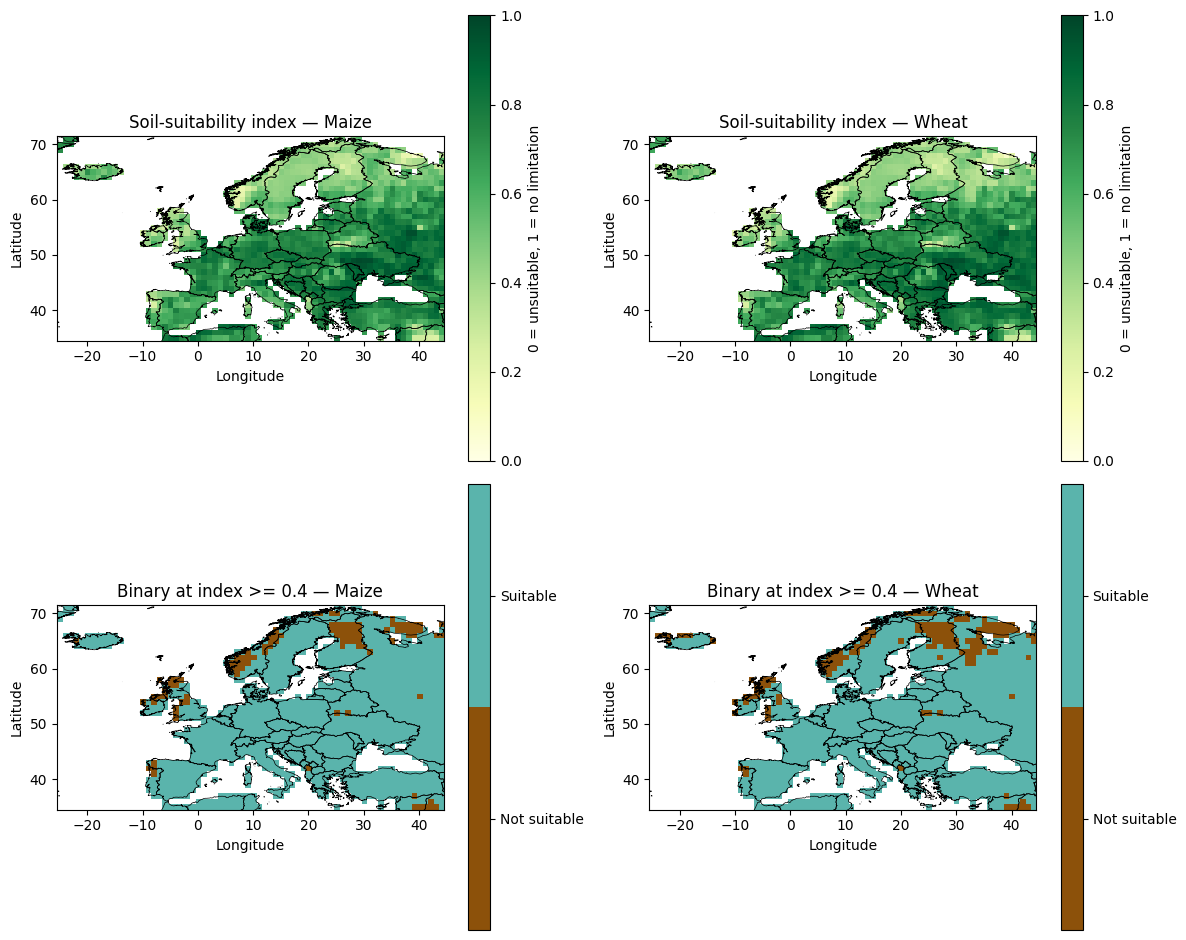

In [13]:
ext = [target_lons[0]-0.5, target_lons[-1]+0.5, target_lats_asc[0]-0.5, target_lats_asc[-1]+0.5]

import matplotlib.colors as mcolors
cmap_bin = mcolors.ListedColormap(['#8c510a', '#5ab4ac'])   # discrete: 0=unsuitable (brown), 1=suitable (teal) — binary data, no gradient

# Spring and winter wheat share one Sys table (Section 4), so their soil layers are identical by
# construction -- show one 'Wheat' panel instead of two redundant ones.
assert np.array_equal(soil_suit_frac['Wheat-spring_rf'], soil_suit_frac['Wheat-winter_rf'], equal_nan=True), (
    "Wheat-spring_rf and Wheat-winter_rf soil layers differ -- update DISPLAY_CROPS below to show both.")
DISPLAY_CROPS = [('Maize_rf', 'Maize'), ('Wheat-spring_rf', 'Wheat')]

fig, axes = plt.subplots(2, len(DISPLAY_CROPS), figsize=(6*len(DISPLAY_CROPS), 9.5))
for k, (crop, label) in enumerate(DISPLAY_CROPS):
    im = axes[0, k].imshow(soil_suit_frac[crop], origin='lower', aspect='auto', extent=ext,
                           cmap='YlGn', vmin=0, vmax=1)
    axes[0, k].set_title(f'Soil-suitability index — {label}')
    plt.colorbar(im, ax=axes[0, k], label='0 = unsuitable, 1 = no limitation')
    im = axes[1, k].imshow(soil_suit_bin[crop], origin='lower', aspect='auto', extent=ext,
                           cmap=cmap_bin, vmin=0, vmax=1)
    axes[1, k].set_title(f'Binary at index >= {TAU_MAP} — {label}')
    cb = plt.colorbar(im, ax=axes[1, k], ticks=[0.25, 0.75])
    cb.ax.set_yticklabels(['Not suitable', 'Suitable'])
for ax in axes.flat:
    ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
    add_coastlines(ax)
plt.tight_layout()
plt.savefig(OUT_DIR / 'soil_suitability_maps.png', dpi=120)
plt.show()

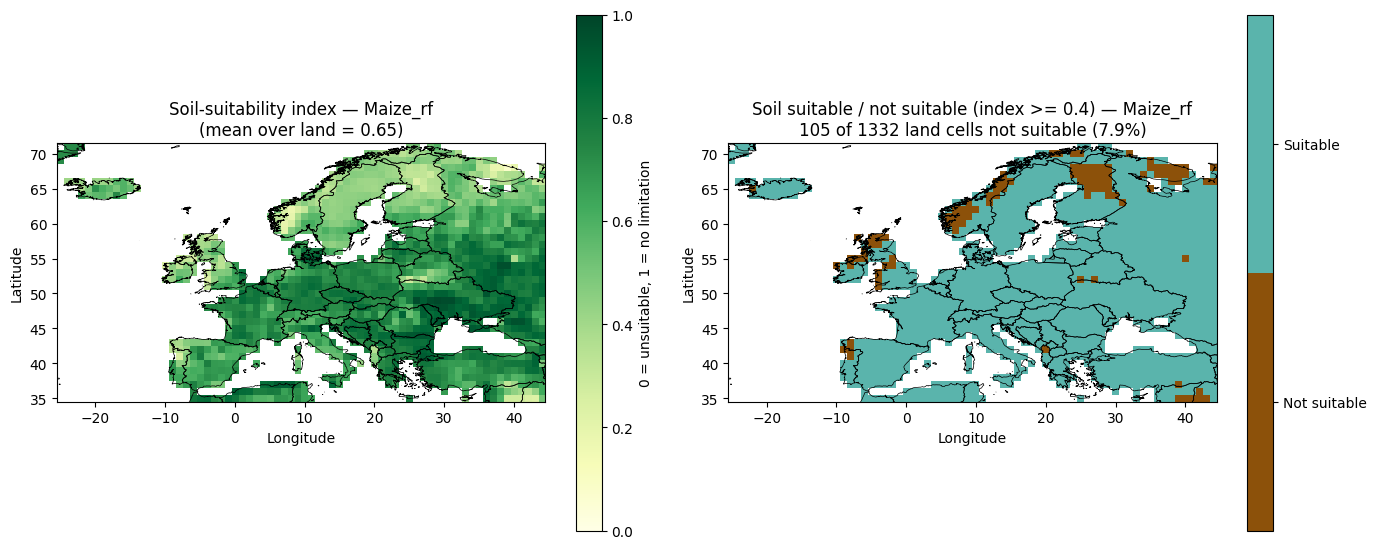

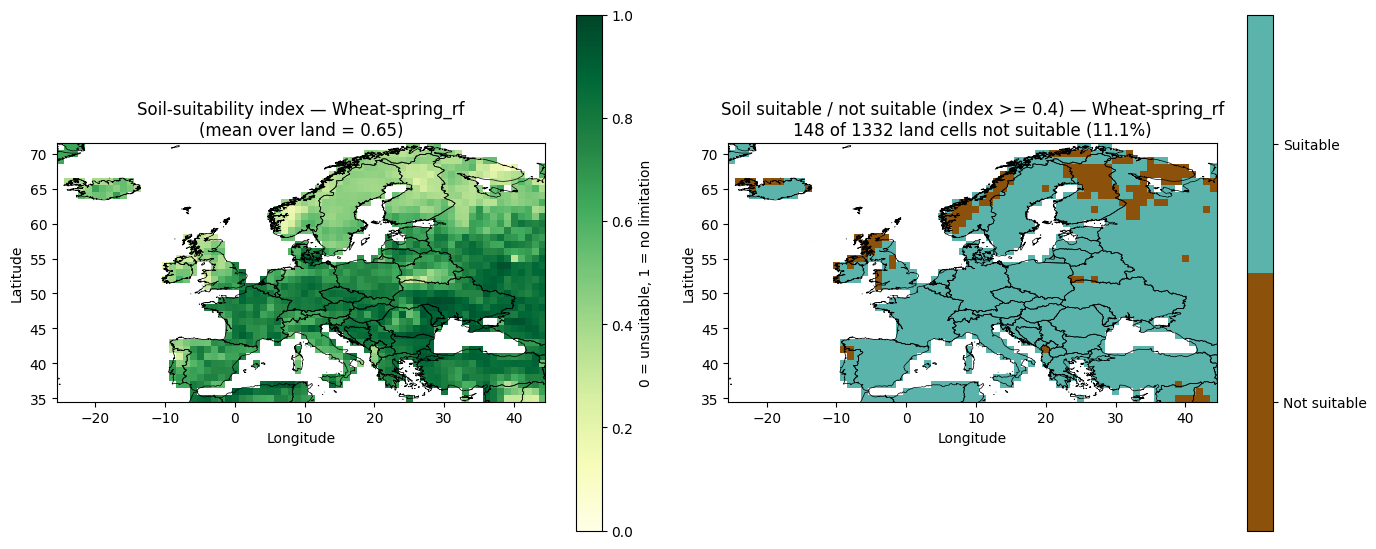

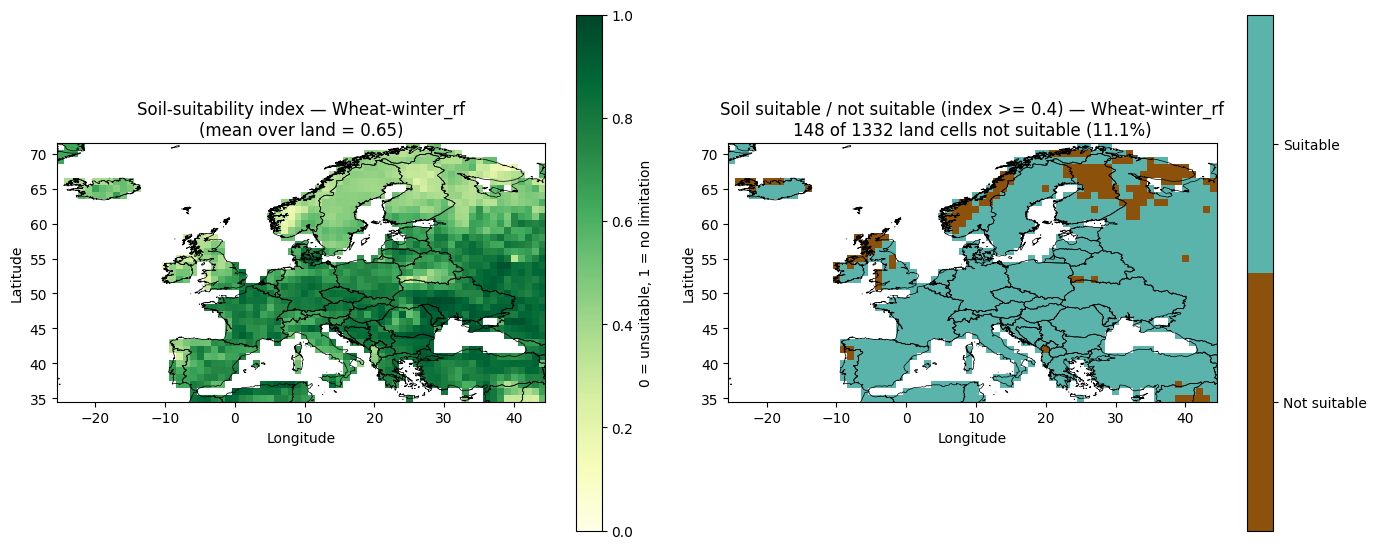

In [14]:
# One figure per crop: SOIL ONLY (no climate component). Left = soil-suitability index (0-1),
# right = binary at TAU_MAP. Ocean / non-land is left white.
import matplotlib.colors as mcolors
cmap_bin = mcolors.ListedColormap(['#8c510a', '#5ab4ac'])
for crop in CROPS:
    f, b = soil_suit_frac[crop], soil_suit_bin[crop]
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))
    im0 = axes[0].imshow(f, origin='lower', aspect='auto', extent=ext, cmap='YlGn', vmin=0, vmax=1)
    axes[0].set_title(f'Soil-suitability index — {crop}\n(mean over land = {np.nanmean(f[land_mask]):.2f})')
    plt.colorbar(im0, ax=axes[0], label='0 = unsuitable, 1 = no limitation')
    im1 = axes[1].imshow(b, origin='lower', aspect='auto', extent=ext, cmap=cmap_bin, vmin=0, vmax=1)
    n_unsuit = int(np.nansum(b == 0))
    axes[1].set_title(f'Soil suitable / not suitable (index >= {TAU_MAP}) — {crop}\n'
                      f'{n_unsuit} of {int(land_mask.sum())} land cells not suitable ({100*n_unsuit/land_mask.sum():.1f}%)')
    cb = plt.colorbar(im1, ax=axes[1], ticks=[0.25, 0.75])
    cb.ax.set_yticklabels(['Not suitable', 'Suitable'])
    for ax in axes:
        ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
        add_coastlines(ax)
    plt.tight_layout()
    plt.savefig(OUT_DIR / f'soil_suitability_map_{crop}.png', dpi=140)
    plt.show()

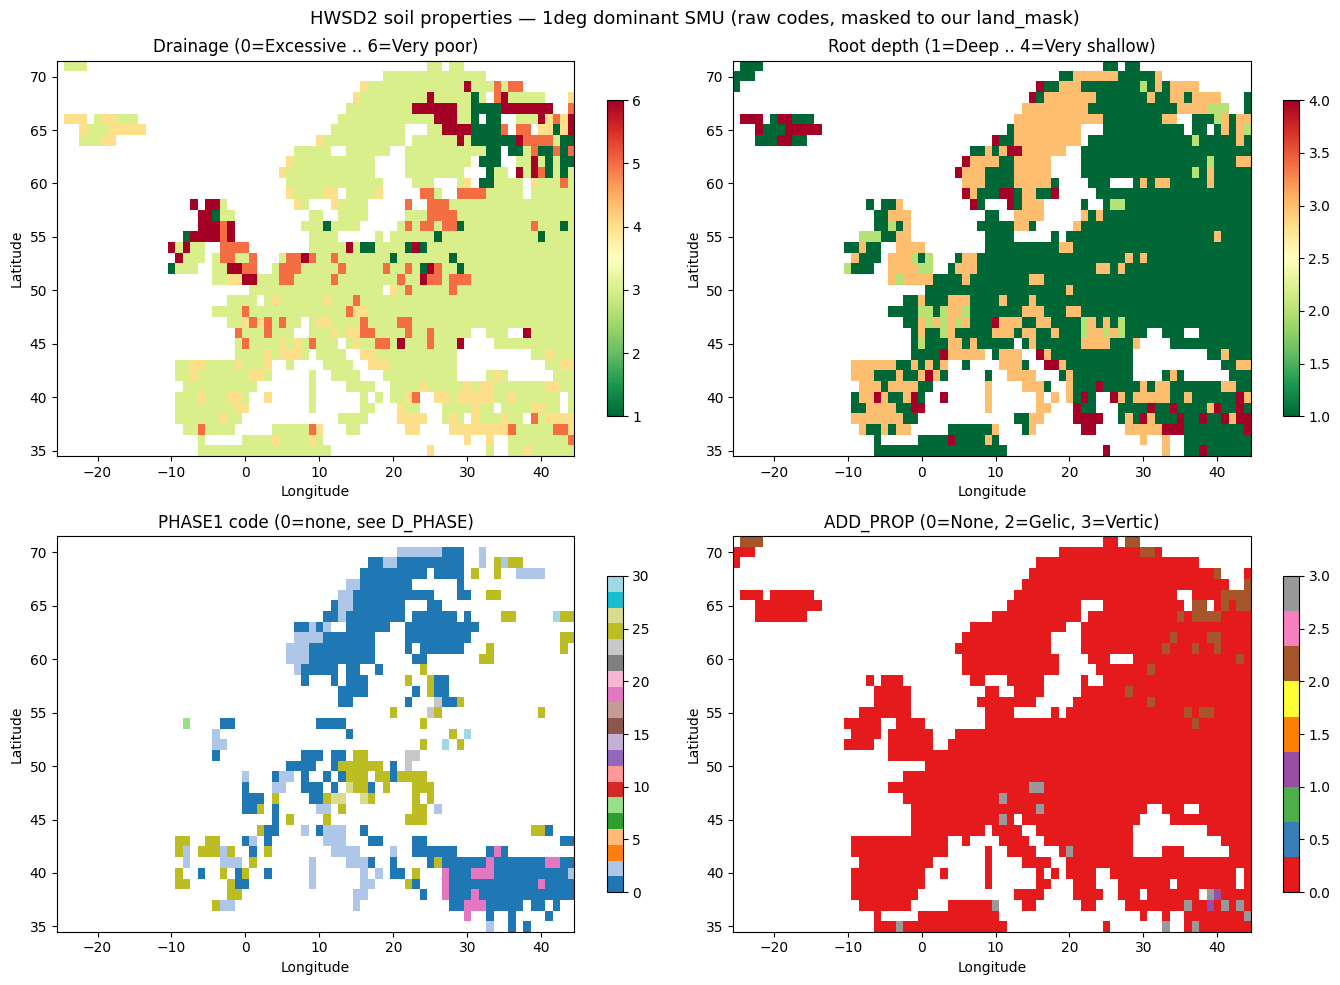

In [15]:
# Per-property diagnostic maps (raw codes) — this is also where the "Norway pattern"
# (Lithic/Stony phases, poor drainage, shallow roots clustering at high latitude, which
# motivated this whole notebook) becomes directly visible.
#
# IMPORTANT: dominant_smu_id (and everything decoded from it) comes from the raw HWSD2
# raster alone, majority-voted with NO reference to our own land_mask -- HWSD2 is a
# global raster and resolves coastlines at 30 arc-sec, so a 1deg cell that is mostly
# ocean by our land_mask (e.g. most of the English Channel) can still contain a few
# HWSD2 land sub-pixels and get a valid dominant SMU_ID. Left unmasked, that makes
# narrow straits (Channel, various fjords) look like solid land in these diagnostic
# plots, even though soil_suit_bin itself (Section 4 onward) is correctly NaN there,
# since rate_crop() gates on land_mask explicitly. Mask by land_mask here too, purely
# for a diagnostic plot that matches what the rest of the pipeline actually treats as land.
drainage_severity_order = {'E': 0, 'SE': 1, 'W': 2, 'MW': 3, 'I': 4, 'P': 5, 'VP': 6}
drainage_severity = np.vectorize(lambda v: drainage_severity_order.get(v, np.nan))(drainage_code)

def masked(arr):
    return np.where(land_mask, arr.astype(float), np.nan)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
panels = [
    (masked(drainage_severity), 'Drainage (0=Excessive .. 6=Very poor)', 'RdYlGn_r'),
    (masked(root_depth_code),   'Root depth (1=Deep .. 4=Very shallow)', 'RdYlGn_r'),
    (masked(phase1_code),       'PHASE1 code (0=none, see D_PHASE)',     'tab20'),
    (masked(add_prop_code),     'ADD_PROP (0=None, 2=Gelic, 3=Vertic)',  'Set1'),
]
for ax, (arr, title, cmap) in zip(axes.flat, panels):
    im = ax.imshow(arr, origin='lower', aspect='auto', extent=ext, cmap=cmap)
    ax.set_title(title); ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
    plt.colorbar(im, ax=ax, shrink=0.8)
plt.suptitle('HWSD2 soil properties — 1deg dominant SMU (raw codes, masked to our land_mask)', fontsize=13)
plt.tight_layout()
plt.savefig(OUT_DIR / 'soil_property_maps.png', dpi=120)
plt.show()

## 9. Reference-point check (the motivating "Norway" observation)

A few known points: high-latitude/mountainous Norway (expected soil-limited for at least
some crops) versus well-known arable regions (expected soil-suitable). Shown as the
soil-suitability index (0-1).

In [16]:
def nearest_idx(lat, lon):
    return int(np.argmin(np.abs(target_lats_asc - lat))), int(np.argmin(np.abs(target_lons - lon)))

POINTS = {
    'Norway - Oslo area (60N,10E)':   (60, 10),
    'Norway - central (65N,14E)':     (65, 14),
    'Norway - far north (68N,16E)':   (68, 16),
    'France (47N,2E)':                (47, 2),
    'Po valley, Italy (45N,10E)':     (45, 10),
    'Ukraine (49N,32E)':              (49, 32),
}

header = f'{"Location":32s}' + ''.join(f'{c:>18s}' for c in CROPS)
print(header)
print('-' * len(header))
for name, (lat, lon) in POINTS.items():
    i, j = nearest_idx(lat, lon)
    row = f'{name:32s}'
    for crop in CROPS:
        row += f'{soil_suit_frac[crop][i, j]:>18.2f}'
    print(row)

Location                                  Maize_rf   Wheat-spring_rf   Wheat-winter_rf
--------------------------------------------------------------------------------------
Norway - Oslo area (60N,10E)                  0.61              0.57              0.57
Norway - central (65N,14E)                    0.35              0.34              0.34
Norway - far north (68N,16E)                  0.47              0.44              0.44
France (47N,2E)                               0.75              0.76              0.76
Po valley, Italy (45N,10E)                    0.82              0.82              0.82
Ukraine (49N,32E)                             0.91              0.91              0.91


## 10. Correction glaciers + resolution fine (2026-10-14)

**Bug trouve en comparant a GAEZ avec l'utilisatrice** : `_SEVERE_PHASE` (Section 4) contient
bien `'Glaciers'`, mais la condition le verifie sur `PHASE1`/`PHASE2` de `HWSD2_SMU` -- verifie
par requete directe : **aucune des 29538 unites de `HWSD2_SMU` n'a PHASE1 ou PHASE2 = Glaciers**
(0 lignes). La regle est donc du code mort. Les vrais glaciers sont encodes ailleurs : le champ
`WRB_PHASES` de `HWSD2_LAYERS` (jamais lu par ce notebook), code `'GG'` (14 composants trouves,
part de surface totale 1190%) -- exactement le meme bug deja trouve et corrige dans
`1_SVM/2_soil_suitability_gaez/2.c)` (voir [[soil-suitability-module-iv-fixes]]), jamais
reporte ici. Meme famille de codes `WRB_PHASES` non-sol a traiter : `'GG'` (glaciers), `'WR'`
(plans d'eau), `'ND'` (no-data), `'IS'` (calotte glaciaire) -- tous forces a note 0 (non arable),
comme dans le module GAEZ.

**Deuxieme changement demande** : au lieu de regrouper a 1deg (perd le detail d'un glacier qui
n'occupe qu'une fraction d'une cellule 1deg), reconstruit a **0.25deg** -- resolution comparable
aux deux autres panneaux de la figure de comparaison (`notre calcul GAEZ` et `GAEZ v5 officiel`,
tous deux a 0.25deg). Meme methode de calcul simple (Sys et al. 1993, pas les formules GAEZ
SQ1-7) -- seule la resolution et la prise en compte des glaciers changent, pas la methodologie.

Garde le fichier/les sorties 1deg existants inchanges -- nouvelle sortie `_0.25deg_glacierfix`
en parallele, rien n'est ecrase.

In [17]:
# Re-requete HWSD2_LAYERS en ajoutant WRB_PHASES (absent de la requete originale de la cellule 13)
MISC_WRB = {'GG', 'WR', 'ND', 'IS'}  # glaciers, plans d'eau, no-data, calotte glaciaire -- non arable

cnxn = cu.hwsd_connect(HWSD_MDB_PATH)
wrb = pd.read_sql("SELECT HWSD2_SMU_ID, SEQUENCE, WRB_PHASES FROM HWSD2_LAYERS WHERE LAYER = 'D1'", cnxn)
cnxn.close()
wrb['WRB_PHASES'] = wrb['WRB_PHASES'].astype(str).str.strip()
comp2 = comp.merge(wrb, on=['HWSD2_SMU_ID', 'SEQUENCE'], how='left')
n_misc = comp2['WRB_PHASES'].isin(MISC_WRB).sum()
print(f"Composants avec WRB_PHASES dans {MISC_WRB} : {n_misc} / {len(comp2)}")
print(comp2.loc[comp2['WRB_PHASES'].isin(MISC_WRB), 'WRB_PHASES'].value_counts())


def rate_components_glacierfix(df, rules):
    """Identique a rate_components (cellule 13), + force note 0 (non arable) pour tout composant
    dont WRB_PHASES est dans MISC_WRB (glaciers/eau/no-data/calotte), quelle que soit la note
    Sys calculee par ailleurs (meme logique que le fix WRB_PHASES de 1_SVM/2_soil_suitability_gaez)."""
    hard = (df['phase1'].isin(rules['exclude_phase']) | df['phase2'].isin(rules['exclude_phase'])
            | df['add_prop'].isin(rules['exclude_add_prop'])
            | df['drainage'].isin(rules['exclude_drainage'])
            | (df['ELEC_COND'] > rules['max_ece']) | (df['ESP'] > rules['max_esp'])
            | (df['TCARBON_EQ'] > rules['max_caco3']) | (df['GYPSUM'] > rules['max_gypsum'])
            | df['WRB_PHASES'].isin(MISC_WRB))
    w_depth   = df['root_depth'].map(rules['depth_weight']).fillna(1.0).values
    w_coarse  = np.select([df['COARSE'] > b for b in COARSE_BREAKS], COARSE_WEIGHTS, default=1.0)
    w_ph      = np.where(df['PH_WATER'].notna().values, ph_weight(df['PH_WATER'].values, rules['ph_bands']), 1.0)
    w_texture = df['sys_texture'].map(rules['texture_rating']).fillna(1.0).values
    out = np.where(hard, 0.0, gaez_blend(w_depth, w_coarse, w_ph, w_texture))
    # WRB_PHASES misc -> toujours 0 (meme si texture manquante, contrairement au NaN habituel) :
    # on SAIT que ce n'est pas du sol arable, ce n'est pas une donnee manquante.
    out = np.where(df['WRB_PHASES'].isin(MISC_WRB).values, 0.0, out)
    out[df['texture'].isna().values & ~df['WRB_PHASES'].isin(MISC_WRB).values] = np.nan
    return out


comp2['suit_Maize_rf_glacierfix'] = rate_components_glacierfix(comp2, SOIL_SUITABILITY_RULES['Maize_rf'])
f_unit_fix = unit_fraction(comp2, 'suit_Maize_rf_glacierfix')
lookup_fix = np.full(65536, np.nan)
lookup_fix[f_unit_fix.index.values.astype(int)] = f_unit_fix.values
print(f"Unites avec note glacierfix calculee : {f_unit_fix.notna().sum()} / {comp2['HWSD2_SMU_ID'].nunique()}")


Composants avec WRB_PHASES dans {'ND', 'WR', 'GG', 'IS'} : 253 / 58405
WRB_PHASES
WR    226
GG     14
ND      7
IS      6
Name: count, dtype: int64
Unites avec note glacierfix calculee : 29164 / 29538


In [18]:
# Reconstruction a 0.25deg (au lieu de 1deg) -- meme logique histogramme pixel-count-weighted
# que regrid_majority_smu_id + cell_fraction (cellules 6 et 13), juste une grille cible plus fine.
RES_FINE = 0.25
SUB = round(1.0 / RES_FINE)  # 4 sous-cellules 0.25deg par cellule 1deg
nlat_f, nlon_f = nlat * SUB, nlon * SUB
fine_lats = (target_lats_asc[:, None] + (np.arange(SUB) + 0.5) / SUB - 0.5).ravel()
fine_lons = (target_lons[:, None] + (np.arange(SUB) + 0.5) / SUB - 0.5).ravel()

with rasterio.open(HWSD_RASTER_PATH) as src:
    res = src.transform.a
    ulx, uly = src.transform.c, src.transform.f
    nodata = src.nodata
    px_per_fine = round(RES_FINE / res)  # pixels natifs (30 arc-sec) par cellule 0.25deg = 30
    col_start = round((LON_MIN_EDGE - ulx) / res)
    row_start = round((uly - LAT_MAX_EDGE) / res)
    col_count = round((LON_MAX_EDGE - LON_MIN_EDGE) / res)
    row_count = round((LAT_MAX_EDGE - LAT_MIN_EDGE) / res)
    arr = src.read(1, window=Window(col_start, row_start, col_count, row_count))

assert arr.shape == (nlat_f * px_per_fine, nlon_f * px_per_fine), f"unexpected shape {arr.shape}"

rating_fine = np.full((nlat_f, nlon_f), np.nan)
for i in range(nlat_f):
    row_block = arr[i * px_per_fine:(i + 1) * px_per_fine, :]
    for j in range(nlon_f):
        block = row_block[:, j * px_per_fine:(j + 1) * px_per_fine].ravel()
        if nodata is not None:
            block = block[block != nodata]
        if block.size == 0:
            continue
        ids, counts = np.unique(block, return_counts=True)
        f = lookup_fix[ids]
        ok = ~np.isnan(f)
        if ok.any():
            rating_fine[i, j] = float((f[ok] * counts[ok]).sum() / counts[ok].sum())

rating_fine = rating_fine[::-1, :]  # raster row 0 = north -> flip to match ascending fine_lats (south->north)
print(f"0.25deg glacierfix grid: {nlat_f} x {nlon_f}, rated cells: {int(np.isfinite(rating_fine).sum())}")
print(f"mean (rated cells) = {np.nanmean(rating_fine):.3f}")

ds_fix = xr.Dataset(
    {'soil_suit_idx_Maize_rf_glacierfix': (('lat', 'lon'), rating_fine)},
    coords={'lat': fine_lats, 'lon': fine_lons},
)
ds_fix.attrs['description'] = (
    'Maize_rf soil suitability (simple Sys et al. 1993 rules, 1_SVM/2_soil_suitability methodology), '
    'rebuilt 2026-10-14 at 0.25deg (vs original 1deg) with WRB_PHASES glacier/water/no-data/ice-sheet '
    'components (GG/WR/ND/IS) forced to 0 -- the original PHASE1/PHASE2-based Glaciers exclusion was '
    'dead code (0 SMUs in HWSD2_SMU actually carry that phase; real glaciers are WRB_PHASES=GG in '
    'HWSD2_LAYERS, never read by this notebook before this fix).'
)
out_path_fix = OUT_DIR / 'soil_suitability_HWSD_0.25deg_glacierfix_Maize_rf.nc'
ds_fix.to_netcdf(out_path_fix)
print(f"Saved: {out_path_fix}")


0.25deg glacierfix grid: 148 x 280, rated cells: 21878
mean (rated cells) = 0.631
Saved: C:\Users\elisa\OneDrive - Politecnico di Milano\PHD_codes\crop_suitability_code_bdap\1_SVM\2_soil_suitability\soil_suitability_outputs\soil_suitability_HWSD_0.25deg_glacierfix_Maize_rf.nc


## 11. Extension de marge pour la figure de comparaison (2026-10-14)

**Bug trouve par l'utilisatrice sur la figure** : la grille 0.25deg de la section 10 est bornee a
lat 35-71 / lon -25-44 (meme domaine que la grille 1deg du pipeline SVM), mais la fenetre
d'affichage de `2.d)` section 8 (`EUROPE_EXTENT = (-26, 46, 33, 73)`) va legerement plus loin --
d'ou une vraie bande sans donnee (lat 33 a 34.625) visible au sud sur le panneau "ancien module",
absente des panneaux 2/3 qui viennent de grilles globales (donc toujours remplies jusqu'au bord de
la vue). Recalcule ici sur EUROPE_EXTENT exactement (marge de securite en plus), sortie separee.

In [19]:
# Meme logique que la section 10 (meme lookup_fix), mais fenetre = EUROPE_EXTENT exactement
# (lon -26 a 46, lat 33 a 73), pas le domaine etroit lat 35-71/lon -25-44 du pipeline SVM.
EUROPE_EXTENT_WIDE = (-26, 46, 33, 73)  # (lon_min, lon_max, lat_min, lat_max), identique a 2.d) section 8

lon_min_w, lon_max_w, lat_min_w, lat_max_w = EUROPE_EXTENT_WIDE
target_lats_w = np.arange(lat_min_w, lat_max_w)   # 33..72 (40 valeurs, edges 33 a 73)
target_lons_w = np.arange(lon_min_w, lon_max_w)   # -26..45 (72 valeurs, edges -26 a 46)
nlat_w, nlon_w = len(target_lats_w), len(target_lons_w)
LAT_MIN_EDGE_W, LAT_MAX_EDGE_W = lat_min_w, lat_max_w
LON_MIN_EDGE_W, LON_MAX_EDGE_W = lon_min_w, lon_max_w

nlat_fw, nlon_fw = nlat_w * SUB, nlon_w * SUB
fine_lats_w = (target_lats_w[:, None] + (np.arange(SUB) + 0.5) / SUB - 0.5).ravel()
fine_lons_w = (target_lons_w[:, None] + (np.arange(SUB) + 0.5) / SUB - 0.5).ravel()

with rasterio.open(HWSD_RASTER_PATH) as src:
    res = src.transform.a
    ulx, uly = src.transform.c, src.transform.f
    nodata = src.nodata
    px_per_fine = round(RES_FINE / res)
    col_start = round((LON_MIN_EDGE_W - ulx) / res)
    row_start = round((uly - LAT_MAX_EDGE_W) / res)
    col_count = round((LON_MAX_EDGE_W - LON_MIN_EDGE_W) / res)
    row_count = round((LAT_MAX_EDGE_W - LAT_MIN_EDGE_W) / res)
    arr_w = src.read(1, window=Window(col_start, row_start, col_count, row_count))

assert arr_w.shape == (nlat_fw * px_per_fine, nlon_fw * px_per_fine), f"unexpected shape {arr_w.shape}"

rating_fine_w = np.full((nlat_fw, nlon_fw), np.nan)
for i in range(nlat_fw):
    row_block = arr_w[i * px_per_fine:(i + 1) * px_per_fine, :]
    for j in range(nlon_fw):
        block = row_block[:, j * px_per_fine:(j + 1) * px_per_fine].ravel()
        if nodata is not None:
            block = block[block != nodata]
        if block.size == 0:
            continue
        ids, counts = np.unique(block, return_counts=True)
        f = lookup_fix[ids]
        ok = ~np.isnan(f)
        if ok.any():
            rating_fine_w[i, j] = float((f[ok] * counts[ok]).sum() / counts[ok].sum())

rating_fine_w = rating_fine_w[::-1, :]
print(f"0.25deg glacierfix grid (EUROPE_EXTENT): {nlat_fw} x {nlon_fw}, rated cells: {int(np.isfinite(rating_fine_w).sum())}")

ds_fix_w = xr.Dataset(
    {'soil_suit_idx_Maize_rf_glacierfix': (('lat', 'lon'), rating_fine_w)},
    coords={'lat': fine_lats_w, 'lon': fine_lons_w},
)
ds_fix_w.attrs['description'] = (
    'Meme calcul que soil_suitability_HWSD_0.25deg_glacierfix_Maize_rf.nc, fenetre elargie a '
    'EUROPE_EXTENT=(-26,46,33,73) (2.d section 8) au lieu du domaine SVM etroit (35-71,-25-44), '
    'pour eviter la bande sans donnee au sud sur la figure de comparaison.'
)
out_path_fix_w = OUT_DIR / 'soil_suitability_HWSD_0.25deg_glacierfix_Maize_rf_wideextent.nc'
ds_fix_w.to_netcdf(out_path_fix_w)
print(f"Saved: {out_path_fix_w}")


0.25deg glacierfix grid (EUROPE_EXTENT): 160 x 288, rated cells: 23533
Saved: C:\Users\elisa\OneDrive - Politecnico di Milano\PHD_codes\crop_suitability_code_bdap\1_SVM\2_soil_suitability\soil_suitability_outputs\soil_suitability_HWSD_0.25deg_glacierfix_Maize_rf_wideextent.nc


In [20]:

# --- TEST CELL (not kept): validate the real-GAEZ-appendix SQ1-SQ7 engine for maize, rainfed,
# against the actual published GAEZ SQ1..SQ7_mze rasters, before wiring into the pipeline.
import sys
sys.path.insert(0, str(BASE / "1_SVM" / "2_soil_suitability"))  # gaez_appendix.py
import importlib
import gaez_appendix as ga
importlib.reload(ga)

ROOT_DEPTH_CM = {'Deep': 120, 'Moderately Deep': 75, 'Shallow': 30, 'Very shallow': 5}
def root_depth_cm(label):
    if label is None: return np.nan
    for k, v in ROOT_DEPTH_CM.items():
        if label.strip().startswith(k): return v
    return np.nan

g = comp.copy()
g['rsd_cm'] = g['root_depth'].map(root_depth_cm)

params = ga.load_crop_params('A6-3.1', 'A6-3.2', 'A6-3.3', 'Maize')
res = ga.rate_gaez(g, params)
for k, v in res.items():
    print(f'{k:8s} mean={np.nanmean(v):.3f} min={np.nanmin(v):.3f} max={np.nanmax(v):.3f} nan={np.isnan(v).sum()}')

g_out = g.assign(**res)


SQ1      mean=0.815 min=0.000 max=1.000 nan=1289
SQ2      mean=0.872 min=0.000 max=1.000 nan=1289
SQ3      mean=0.793 min=0.000 max=1.000 nan=1289
SQ4      mean=0.920 min=0.000 max=1.000 nan=1289
SQ5      mean=0.896 min=0.000 max=1.000 nan=1289
SQ6      mean=0.882 min=0.000 max=1.000 nan=1289
SQ7      mean=0.839 min=0.000 max=1.000 nan=1289
SR_low   mean=0.752 min=0.000 max=1.167 nan=1289
SR_int   mean=0.780 min=0.000 max=1.167 nan=1289
SR_high  mean=0.808 min=0.000 max=1.167 nan=1289


In [21]:

# Aggregate SQ1..SQ7 + SR_high to the 1deg grid and correlate each against the real GAEZ
# SQx_mze_v9aH raster (same block-mean decoder as 2.b)'s load_gaez_sq0: codes 0-9 -> band
# midpoint (code+0.5)/10, everything else -> NaN).
import rasterio
from rasterio.windows import Window

def regrid_field(colname):
    f_unit = unit_fraction(g_out, colname)
    lookup = np.full(65536, np.nan)
    lookup[f_unit.index.values.astype(int)] = f_unit.values
    raw = cell_fraction(smu_hist, lookup)
    return np.where(land_mask, raw, np.nan)

def load_gaez_class_tif(path):
    with rasterio.open(path) as src:
        res = src.transform.a
        ulx, uly = src.transform.c, src.transform.f
        px_per_deg = round(1.0 / res)
        col_start = round((LON_MIN_EDGE - ulx) / res)
        row_start = round((uly - LAT_MAX_EDGE) / res)
        col_count = round((LON_MAX_EDGE - LON_MIN_EDGE) / res)
        row_count = round((LAT_MAX_EDGE - LAT_MIN_EDGE) / res)
        raw = src.read(1, window=Window(col_start, row_start, col_count, row_count))
    score = np.where(raw <= 9, (raw.astype(float) + 0.5) / 10.0, np.nan)
    blocks = score.reshape(nlat, px_per_deg, nlon, px_per_deg)
    with np.errstate(invalid='ignore'):
        out = np.nanmean(blocks, axis=(1, 3))[::-1, :]
    return np.where(land_mask, out, np.nan)

GAEZ_DIR = BASE / "0_Input_data" / "gaez"
for sq in ['SQ1', 'SQ2', 'SQ3', 'SQ4', 'SQ5', 'SQ6', 'SQ7']:
    ours = regrid_field(sq)
    p = GAEZ_DIR / f'{sq}_mze_v9aH.tif'
    if not p.exists():
        print(sq, 'GAEZ raster missing'); continue
    gaez = load_gaez_class_tif(p)
    both = np.isfinite(ours) & np.isfinite(gaez) & land_mask
    r = np.corrcoef(ours[both], gaez[both])[0, 1] if both.sum() > 5 else np.nan
    print(f'{sq}: ours mean={np.nanmean(ours[both]):.3f}  GAEZ mean={np.nanmean(gaez[both]):.3f}  '
          f'r={r:.3f}  n={int(both.sum())}')

ours_high = regrid_field('SR_high')
gaez_sq0 = load_gaez_class_tif(GAEZ_DIR / 'SQ0_mze_v9aH.tif')
both = np.isfinite(ours_high) & np.isfinite(gaez_sq0) & land_mask
print('SR_high vs SQ0:', 'r=', np.corrcoef(ours_high[both], gaez_sq0[both])[0,1], 'n=', int(both.sum()))


SQ1: ours mean=0.787  GAEZ mean=0.711  r=0.439  n=1312
SQ2: ours mean=0.830  GAEZ mean=0.743  r=0.117  n=1223
SQ3: ours mean=0.742  GAEZ mean=0.689  r=0.245  n=1181
SQ4: ours mean=0.886  GAEZ mean=0.540  r=0.054  n=775
SQ5: ours mean=0.900  GAEZ mean=0.365  r=0.138  n=526


SQ6: ours mean=0.857  GAEZ mean=0.284  r=-0.030  n=458
SQ7: ours mean=0.807  GAEZ mean=0.651  r=0.208  n=1141


SR_high vs SQ0: r= 0.6298835522251395 n= 1320
